# Ukraine, its allies and Russia on Reddit: 2019 vs 2022
## Homework #3 — Exploratory Data Analysis · Team 12

**Authors:** Yevhenia Kravchenko, Mykhailo Kurta

**Time spent on this homework:** ___ hours in total

Course project: *Dynamics of Discussions about Allied Countries, International Support for Ukraine, and Reactions to Russian Aggression on Reddit.*

## 1. Overview

### 1.1 The dataset

The data was collected and cleaned in Homework #2 (`Data_parsing/`). It covers **eight subreddits** (r/worldnews, r/europe, r/ukraine, r/UkrainianConflict, r/UkraineWarReport, r/geopolitics, r/CredibleDefense, r/NATO) in two years:

* **2019** — a peacetime baseline (the same calendar months, so seasonality does not bias the comparison);
* **2022** — split into **before the invasion** (1 Jan – 23 Feb) and **after the invasion** (24 Feb – 31 Dec).

A record is kept when its text is about Ukraine (or about Russia together with an aggression term), or when it is a comment in an on-topic thread or in a war-dedicated subreddit that carries its own topic signal. Every record has:

| Group | Columns | Used here for |
|---|---|---|
| Record | `type`, `subreddit`, `date`, `score`, `thread_id`, `thread_n`, `text` | volume, timing, structure, length, upvotes |
| Why it is in the data | `topic_source`, `us_domestic`, `is_lifestyle` | dataset composition, noise control |
| Who is mentioned | `countries`, `organizations`, `countries_focus` | attention to each country |
| Kind of support | `aid_military` … `membership`, `country_support` | what kind of help is discussed, by whom |
| Denominators | `subreddit_day_total`, `subreddit_month_total` | share of *all* subreddit activity |
| Tone | `reaction_ukraine`, `reaction_russia`, `reaction` | how each country is talked about (−1 / 0 / +1) |

The tone labels come from a DeBERTa-v3 aspect-based sentiment model that we fine-tuned on 1,600 hand-labelled (text, country) pairs; its accuracy is checked in Section 5.

### 1.2 Submissions and comments: separately and together

The dataset already stores submissions and comments in **one table** with a `type` column; a comment is linked to its submission through `thread_id`, and a submission's text is its title plus body. We use both views:

* **Separately** for everything where the two behave differently by nature — volume, scores, text length (Figures 1, 12, 13).
* **Merged** for content and tone: a post and a comment are both one person's statement about the war, so for "who is discussed", "what support" and "with which tone" every record counts as one statement. To stop a few megathreads with tens of thousands of comments from dominating, tone estimates weight each record by 1/√thread_n (thread_n = records from the same thread).

**Analysis base.** Records flagged `us_domestic` (US domestic politics, e.g. the 2019 impeachment) or `is_lifestyle` (travel, food, language) stay in the data for the volume analysis, but are excluded from the content and tone analysis ("core" records).

### 1.3 Questions and hypotheses

| # | Question | Hypothesis |
|---|---|---|
| Q1 | How much bigger is the discussion in 2022 than in 2019, and does the growth survive normalising by overall subreddit activity? | **H1.** 2022 volume is at least ten times the 2019 level, also as a share of all subreddit activity. |
| Q2 | Which events produce spikes, and how fast does attention decay after the invasion? | **H2.** Activity peaks in the first days of the invasion, then decays, with smaller spikes at major events (Bucha, mobilisation, Kherson). |
| Q3 | Which communities carry the discussion, and does the mix change after 24 February? | **H3.** In 2019 Ukraine was discussed largely through US domestic politics (the Trump–Zelensky call and impeachment). |
| Q4 | Is the conversation concentrated in a few megathreads? How do posts and comments differ? | **H4.** Wartime discussion is far more concentrated in megathreads than in 2019. |
| Q5 | Which countries are discussed, and how does their share of attention move through 2022? | **H5.** Attention shifts from the USA towards European neighbours (Poland, Germany) and towards countries tied to specific events (Turkey, Finland). |
| Q6 | Which kinds of support dominate, and which country is linked to which kind? | **H6.** Military aid and sanctions dominate after the invasion; energy rises in autumn. |
| Q7 | How does the tone towards Ukraine, Russia and individual countries change? | **H7.** Tone towards Ukraine becomes more positive and towards Russia more negative; countries seen as obstructing help (Hungary) get more negative, frontline supporters (Poland, UK, Baltics) more positive. |
| Q8 | Do countries that get more attention also get a warmer tone? | **H8.** Countries that are discussed more after the invasion are also talked about more warmly. |
| Q9 | Which comments does Reddit reward with upvotes? | **H9.** Comments that support Ukraine or criticise Russia get more upvotes than neutral ones. |

Section 7 checks each hypothesis against the figures.

### 1.4 Setup

Run the notebook from the repository root (next to `Data_parsing/`). To keep the report readable, the reusable parts live in `eda_assets/`:

* `eda_utils.py` — plotting style, the figure frame, data loading with a cache, tone and word statistics, map drawing;
* `eda_config.json` — settings and reference data: colours, real-world event dates, keyword lists, labels;
* `countries.json` — country shapes for the maps (Natural Earth, public domain; Crimea drawn as part of Ukraine).

The first run reads the full CSV once in chunks and stores a compact cache (`Data_parsing/data/eda_cache.pkl`); later runs start in seconds. Only `pandas`, `numpy` and `matplotlib` are needed.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

from eda_assets.eda_utils import *   # style, helpers, data loading and maps (eda_assets/eda_utils.py)

matplotlib 3.11.2 | pandas 3.0.6 | font: Segoe UI | map shapes: ok


### 1.5 Loading the data

The CSV is several gigabytes, so it is read once in chunks. From each chunk we keep compact numeric columns plus four "long" tables (one row per record × country): countries in focus, all country mentions, tone per country and support type per country. Keyword flags for named people, themes and weapons are computed on the full text at the same time, and a random sample of texts per period is kept for the word analysis.

Tables used below: `R` — all records; `CORE` — records without US-domestic and lifestyle ones; `FOCUS` — countries in focus; `RC` — tone pairs (record × country); `SUPP` — support type per country; `SAMPLE` — texts for the word analysis.

In [2]:
D = load_data()
R, CORE, FOCUS, MENT, RC, SUPP, SAMPLE, N_CORE = (D[k] for k in ("R", "CORE", "FOCUS", "MENT", "RC", "SUPP", "SAMPLE", "N_CORE"))
REACTIONS_DIR = D["REACTIONS_DIR"]

Data: Data_parsing\data\reddit_ukraine_support.csv
7,791,376 records · 7,695,680 core records · 2,015,630 country mentions in focus · 10,439,478 labelled (record, country) tone pairs


### 1.6 Data card

In [3]:
card = []
for p in PERIODS:
    x = R[R["period"] == p]
    days = (x["date"].max() - x["date"].min()).days + 1
    card.append({
        "Period": PERIOD_LABEL[p],
        "Dates": f"{x['date'].min():%d %b %Y} – {x['date'].max():%d %b %Y}",
        "Days": days,
        "Records": f"{len(x):,}",
        "Submissions": f"{(x['type'] == 'submission').sum():,}",
        "Comments": f"{(x['type'] == 'comment').sum():,}",
        "Threads": f"{x['thread'].nunique():,}",
        "Records / day": f"{len(x) / days:,.0f}",
        "US-domestic": f"{x['usd'].mean():.1%}",
        "Lifestyle": f"{x['life'].mean():.1%}",
        "Core records": f"{x['core'].sum():,}",
    })
display(pd.DataFrame(card).set_index("Period").T)

fill = pd.DataFrame({
    "Field": ["countries_focus (≥1 country in focus)", "countries / organizations (any mention)",
              "any support-type flag", "country_support (support linked to a country)",
              "reaction_ukraine", "reaction_russia", "author_country (from flair or text)"],
    "Share of core records": [
        FOCUS["row"].nunique() / len(CORE), MENT["row"].nunique() / len(CORE),
        CORE[[f"s_{s}" for s in SUPPORT]].any(axis=1).mean(), SUPP["row"].nunique() / len(CORE),
        CORE["r_ua"].notna().mean(), CORE["r_ru"].notna().mean(), (CORE["auth"] != "(unknown)").mean()],
})
fill["Share of core records"] = fill["Share of core records"].map(lambda v: f"{v:.1%}")
display(fill.set_index("Field"))

Period,2019,"2022, before 24 Feb","2022, from 24 Feb"
Dates,01 Jan 2019 – 31 Dec 2019,01 Jan 2022 – 23 Feb 2022,24 Feb 2022 – 31 Dec 2022
Days,365,54,311
Records,"153,440","459,499","7,178,437"
Submissions,"12,407","13,566","310,417"
Comments,"141,033","445,933","6,868,020"
Threads,"25,079","18,917","383,895"
Records / day,420,"8,509","23,082"
US-domestic,29.7%,0.3%,0.2%
Lifestyle,1.8%,0.5%,0.4%
Core records,"105,339","455,886","7,134,455"


,Share of core records
Field,
countries_focus (≥1 country in focus),19.1%
countries / organizations (any mention),33.6%
any support-type flag,24.5%
country_support (support linked to a country),10.6%
reaction_ukraine,42.2%
reaction_russia,67.3%
author_country (from flair or text),5.2%


The 2022 pre-war period is short (54 days), so periods are always compared through **rates** (records per day, shares, mentions per 1,000 records), never through raw totals.

## 2. Activity: when and where people talked

### 2.1 How much more discussion was there in 2022? (Q1)

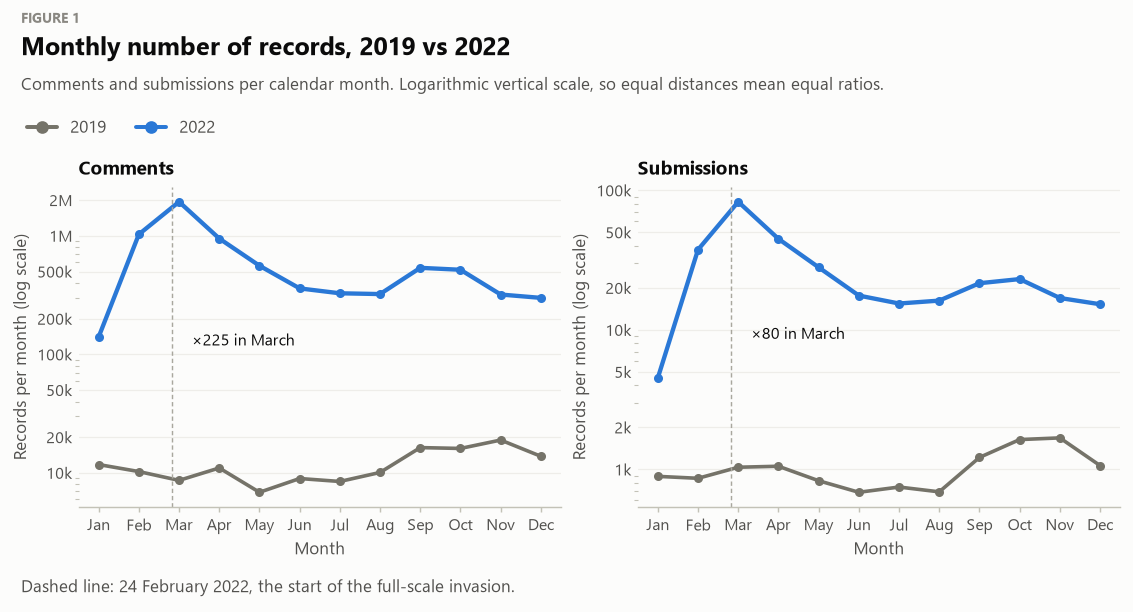

In [4]:
m = R.groupby(["year", "mon", "type"], observed=True).size().rename("n").reset_index()
FIGREF["volume"] = FIG["n"] + 1
fig, axes = frame("Monthly number of records, 2019 vs 2022",
                  "Comments and submissions per calendar month. Logarithmic vertical scale, so equal distances mean equal ratios.",
                  ncols=2, h=3.7, legend=([line_h(C19, marker="o"), line_h(BLUE, marker="o")], ["2019", "2022"]),
                  note="Dashed line: 24 February 2022, the start of the full-scale invasion.")
for ax, t, name in zip(axes, ["comment", "submission"], ["Comments", "Submissions"]):
    s = {y: m[(m["year"] == y) & (m["type"] == t)].set_index("mon")["n"].reindex(range(1, 13)) for y in (2019, 2022)}
    ax.plot(s[2019].index, s[2019].values, color=C19, marker="o", ms=4)
    ax.plot(s[2022].index, s[2022].values, color=BLUE, marker="o", ms=4, lw=2.4)
    ax.set_yscale("log")
    log_ticks(ax.yaxis)
    ax.axvline(2 + 23 / 28, color="#a9a79e", lw=0.8, ls=(0, (3, 2)))
    month_index_axis(ax)
    ax.set_title(name)
    ax.set_xlabel("Month")
    ax.set_ylabel("Records per month (log scale)")
    if s[2019][3] > 0 and s[2022][3] > 0:
        ax.annotate(f"×{s[2022][3] / s[2019][3]:.0f} in March", xy=(3, np.sqrt(s[2022][3] * s[2019][3])),
                    xytext=(7, 0), textcoords="offset points", fontsize=8.6, color=INK, va="center")
plt.show()

by_m = m.groupby(["year", "mon"])["n"].sum().unstack(0)
y19, y22 = (R["year"] == 2019).sum(), (R["year"] == 2022).sum()
peak = int(by_m[2022].idxmax())
FACTS.update(ratio_year=y22 / y19, peak_month=MONTHS_FULL[peak - 1],
             ratio_peak=by_m.loc[peak, 2022] / by_m.loc[peak, 2019], ratio_dec=by_m.loc[12, 2022] / by_m.loc[12, 2019],
             ratio_jan=by_m.loc[1, 2022] / by_m.loc[1, 2019])
say(f"**{len(R):,} records** in total: {y19:,} in 2019 and {y22:,} in 2022 — **×{y22 / y19:.0f}**.",
    f"Comments are {(R['type'] == 'comment').mean():.0%} of all records; there are "
    f"{(R['type'] == 'comment').sum() / max((R['type'] == 'submission').sum(), 1):.0f} comments per submission.",
    f"The busiest month is **{MONTHS_FULL[peak - 1]} 2022** with {by_m.loc[peak, 2022]:,.0f} records, "
    f"×{FACTS['ratio_peak']:.0f} the same month of 2019.",
    (f"January 2022 is already ×{FACTS['ratio_jan']:.1f} January 2019: the Russian troop build-up and US warnings "
     f"about an imminent invasion were in the news before 24 February." if FACTS["ratio_jan"] > 1.3 else
     f"January 2022 is close to January 2019 (×{FACTS['ratio_jan']:.1f}): the troop build-up had not yet moved Reddit much."),
    (f"December 2022 is still ×{FACTS['ratio_dec']:.0f} December 2019 — attention decayed after spring, "
     f"but never came close to the peacetime level." if FACTS["ratio_dec"] > 2 else
     f"By December 2022 the volume is ×{FACTS['ratio_dec']:.1f} December 2019 — close to the peacetime level again."))

**What we see.** The blue 2022 line is far above the grey 2019 line in every month, for both comments and posts. It climbs sharply in February, reaches its top in March and then slowly goes down, with a small rise again in autumn.

**What it means.** The war made Ukraine one of the main topics on these subreddits. Interest was highest at the start of the invasion, and even at the end of the year it stayed many times higher than in peacetime.

Raw counts mix two things: more interest in Ukraine and a growing Reddit. Each record carries `subreddit_month_total`, the number of **all** texts in the subreddit that month, so we can divide by it and see what share of each community's activity was about Ukraine.

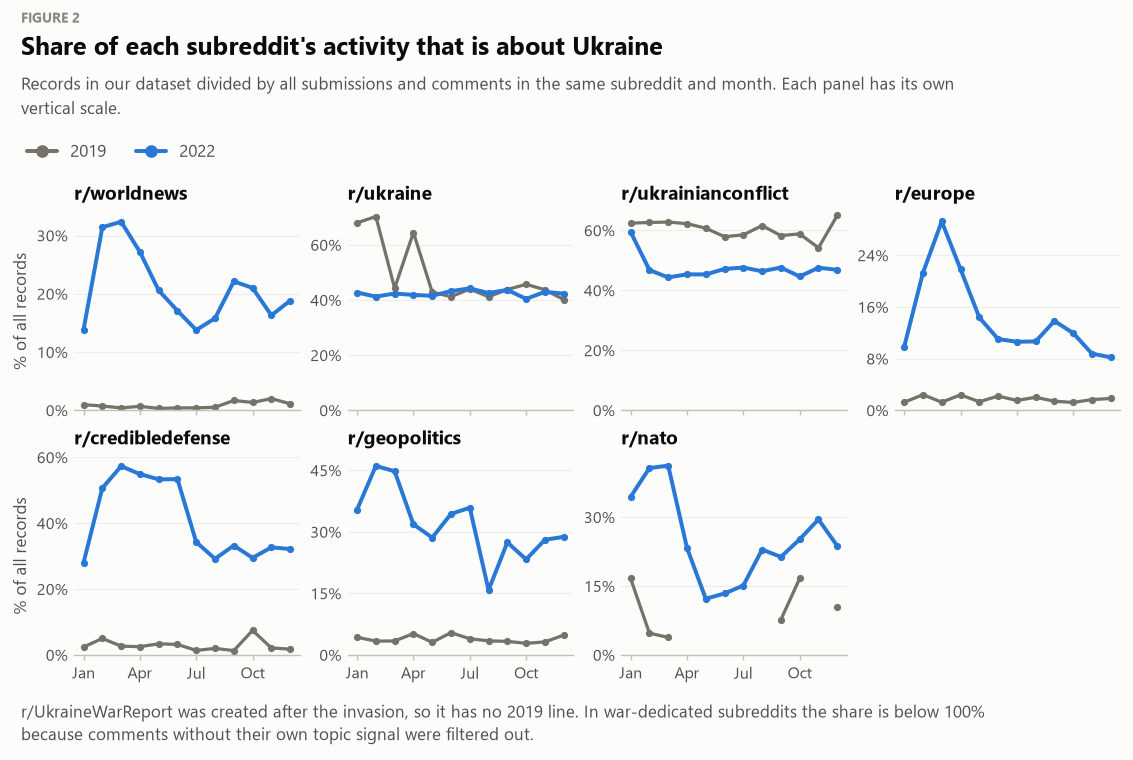

In [5]:
g = (R.groupby(["sub", "type", "year", "mon"], observed=True)
       .agg(n=("smt", "size"), total=("smt", "max")).reset_index())
g = g.groupby(["sub", "year", "mon"], observed=True)[["n", "total"]].sum().reset_index()
g = g[g["total"] > 0]
g["share"] = g["n"] / g["total"] * 100
SUB_ORDER = [s for s, n in R["sub"].value_counts().items() if n >= 200]
SUB_COLOR = {s: (SUB_COLORS[i] if i < len(SUB_COLORS) else OTHER) for i, s in enumerate(SUB_ORDER)}
subs = SUB_ORDER[:8]
nr = int(np.ceil(len(subs) / 4))
FIGREF["share"] = FIG["n"] + 1
fig, axes = frame("Share of each subreddit's activity that is about Ukraine",
                  "Records in our dataset divided by all submissions and comments in the same subreddit and month. "
                  "Each panel has its own vertical scale.",
                  nrows=nr, ncols=4, h=2.3 * nr, sharex=True,
                  legend=([line_h(C19, marker="o"), line_h(BLUE, marker="o")], ["2019", "2022"]),
                  note="r/UkraineWarReport was created after the invasion, so it has no 2019 line. In war-dedicated "
                       "subreddits the share is below 100% because comments without their own topic signal were filtered out.")
axes = np.atleast_1d(axes).ravel()
norm_rows = []
for ax, s in zip(axes, subs):
    for y, c, lw in ((2019, C19, 1.8), (2022, BLUE, 2.2)):
        t = g[(g["sub"] == s) & (g["year"] == y)].set_index("mon")["share"].reindex(range(1, 13))
        ax.plot(t.index, t.values, color=c, lw=lw, marker="o", ms=3)
    ax.set_title(f"r/{s}")
    ax.set_ylim(bottom=0)
    top = ax.get_ylim()[1]
    ax.yaxis.set_major_formatter(pct_fmt())
    ax.yaxis.set_major_locator(MaxNLocator(4))
    month_index_axis(ax, short=True)
    a = g[(g["sub"] == s) & (g["year"] == 2019)]
    b = g[(g["sub"] == s) & (g["year"] == 2022) & (g["mon"] >= 3)]
    s19 = a["n"].sum() / a["total"].sum() * 100 if a["total"].sum() else np.nan
    s22 = b["n"].sum() / b["total"].sum() * 100 if b["total"].sum() else np.nan
    norm_rows.append((s, s19, s22))
for ax in axes[len(subs):]:
    ax.set_visible(False)
for ax in axes[::4]:
    ax.set_ylabel("% of all records")
plt.show()

nr_df = pd.DataFrame(norm_rows, columns=["sub", "s19", "s22"]).dropna()
nr_df["x"] = nr_df["s22"] / nr_df["s19"]
FACTS["norm_ratio_median"] = nr_df["x"].median()
say(*[f"r/{r.sub}: {r.s19:.2f}% of all activity in 2019 → {r.s22:.2f}% in March–December 2022 (×{r.x:.0f})."
      for r in nr_df.sort_values("x", ascending=False).itertuples()],
    f"Median growth of the share across subreddits: **×{FACTS['norm_ratio_median']:.1f}**. " +
    ("The increase is not just Reddit growing: Ukraine took a much larger slice of each community's attention."
     if FACTS["norm_ratio_median"] > 1.5 else
     "Once overall activity is taken into account, the growth is modest: much of the raw increase is Reddit growing."))

**What we see.** In r/worldnews, r/europe, r/geopolitics and r/CredibleDefense the 2022 line is far above the 2019 line: Ukraine went from a tiny part of their activity to a large one. In r/ukraine and r/UkrainianConflict both lines are at a similar level.

**What it means.** The growth is real interest, not just Reddit getting bigger: general news and politics communities started to talk about Ukraine much more. The Ukrainian subreddits were always about Ukraine — they simply got many more users.

### 2.2 The rhythm of 2022: spikes and decay (Q2)

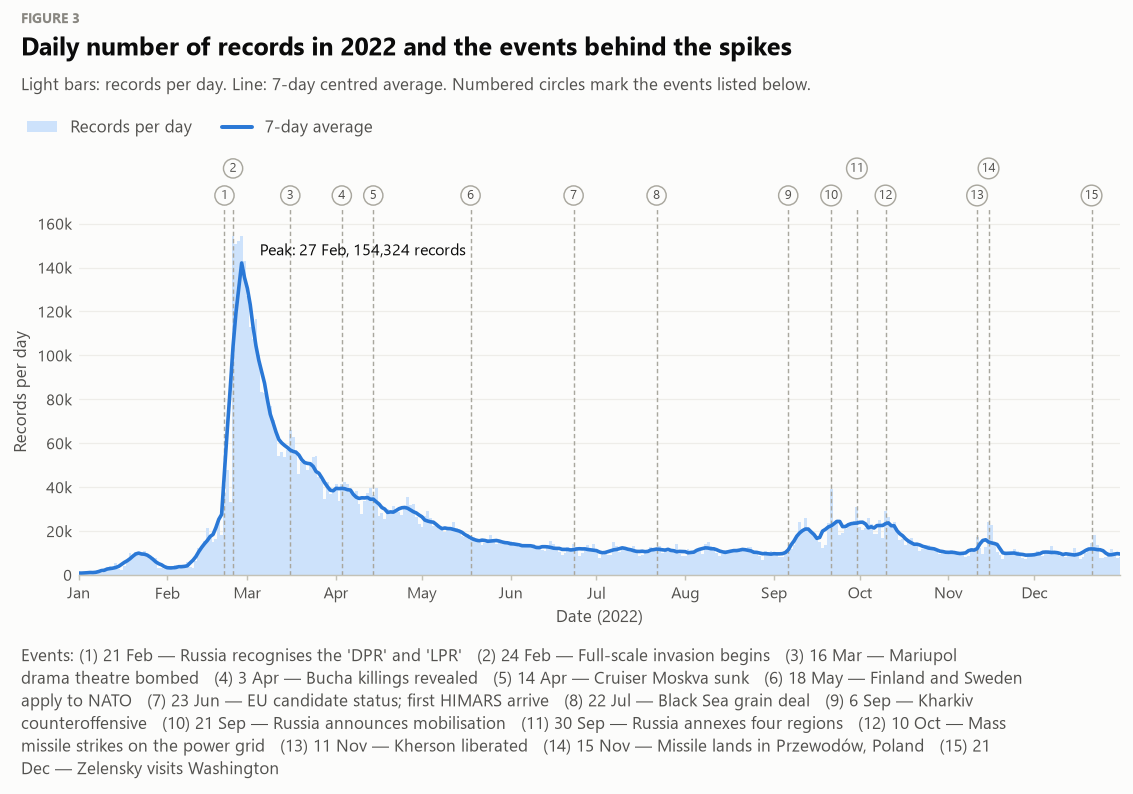

In [6]:
d22 = R[R["year"] == 2022].groupby("date").size()
d22 = d22.reindex(pd.date_range("2022-01-01", "2022-12-31"), fill_value=0)
roll = d22.rolling(7, center=True, min_periods=4).mean()
FIGREF["daily"] = FIG["n"] + 1
fig, ax = frame("Daily number of records in 2022 and the events behind the spikes",
                "Light bars: records per day. Line: 7-day centred average. Numbered circles mark the events listed below.",
                h=4.3, note=event_key(EV2022),
                legend=([patch_h(BLUE_LIGHT), line_h(BLUE)], ["Records per day", "7-day average"]))
ax.bar(d22.index, d22.values, width=1.0, color=BLUE_LIGHT, linewidth=0)
ax.plot(roll.index, roll.values, color=BLUE, lw=2)
month_axis(ax)
ax.set_ylim(0, d22.max() * 1.08)
ax.yaxis.set_major_formatter(FuncFormatter(human))
ax.set_ylabel("Records per day")
ax.set_xlabel("Date (2022)")
mark_events(ax, EV2022)
pk = d22.idxmax()
ax.annotate(f"Peak: {day_month(pk)}, {d22[pk]:,} records", xy=(pk, d22[pk]), xytext=(10, -4),
            textcoords="offset points", fontsize=8.6, color=INK, va="top")
plt.show()

jan = d22.loc["2022-01-01":"2022-02-20"].mean()
wk1 = d22.loc["2022-02-24":"2022-03-02"].mean()
r_peak = roll.max()
after = roll[roll.idxmax():]
half = after[after < r_peak / 2]
half_day = half.index[0] if len(half) else None
FACTS.update(peak_day=pk, peak_day_n=int(d22[pk]), first_week_ratio=wk1 / jan if jan else np.nan,
             half_days=(half_day - roll.idxmax()).days if half_day is not None else None,
             dec_vs_mar=d22.loc["2022-12"].mean() / d22.loc["2022-03"].mean())
say(f"The single busiest day is **{pk:%d %B}** with {d22[pk]:,} records.",
    f"In the first week of the invasion (24 Feb – 2 Mar) there were {wk1:,.0f} records per day, "
    f"×{FACTS['first_week_ratio']:.0f} the January–mid-February average ({jan:,.0f} per day).",
    (f"The 7-day average fell to half of its peak after **{FACTS['half_days']} days** ({day_month(half_day)})."
     if half_day is not None else "The 7-day average never fell below half of its peak."),
    f"December's daily volume is {FACTS['dec_vs_mar']:.0%} of March's.")

**What we see.** One huge spike at the end of February, then a fast fall during March and April. After that the line is low and flat, with small waves in September–October and in November.

**What it means.** The invasion caused the biggest wave of attention of the whole year. Later events still brought people back, but never on the same scale.

Which events actually moved the conversation? For every event we compare the average number of records in the **three days starting on the event** with the **seven days before it**. A ratio of ×2 means activity doubled.

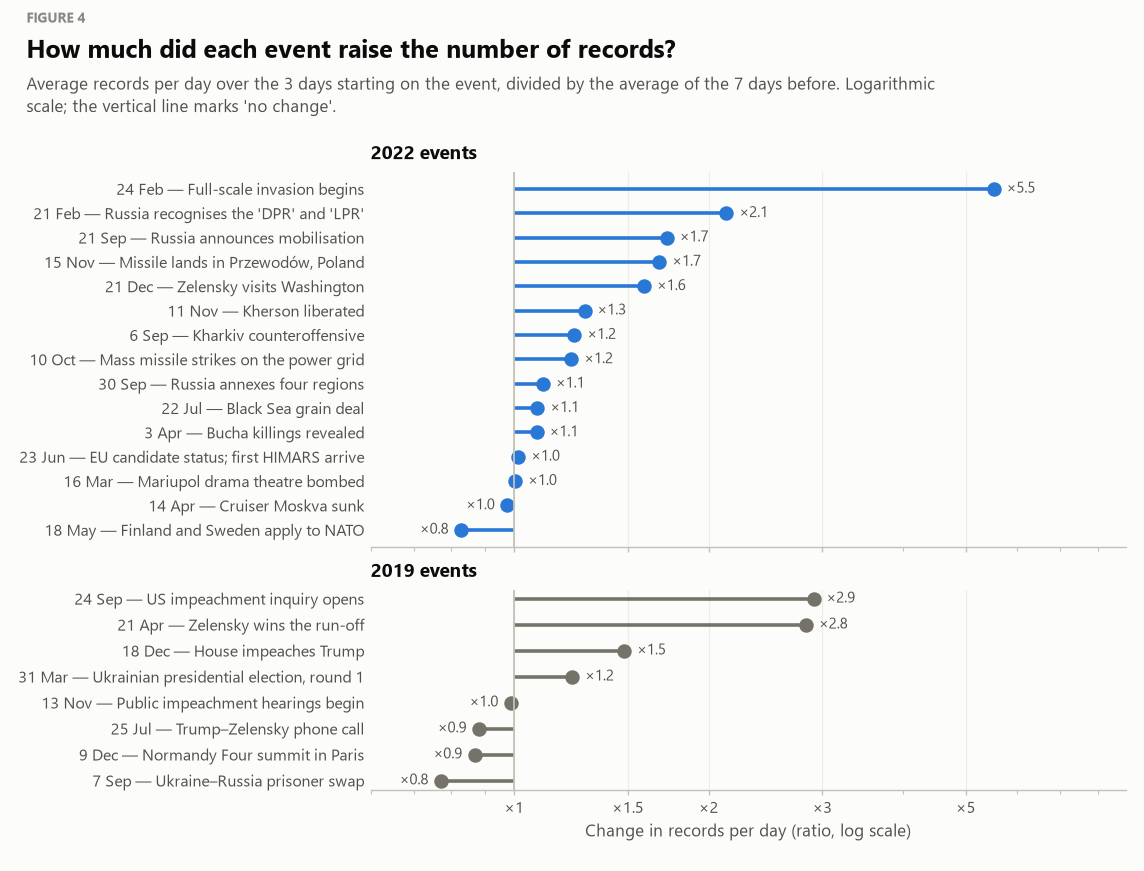

In [7]:
d19 = R[R["year"] == 2019].groupby("date").size()
d19 = d19.reindex(pd.date_range("2019-01-01", "2019-12-31"), fill_value=0)


eff22, eff19 = event_effect(d22, EV2022), event_effect(d19, EV2019)
FIGREF["events"] = FIG["n"] + 1
fig, axes = frame("How much did each event raise the number of records?",
                  "Average records per day over the 3 days starting on the event, divided by the average of the 7 days before. "
                  "Logarithmic scale; the vertical line marks 'no change'.",
                  nrows=2, h=6.4, sharex=True, gridspec_kw={"height_ratios": [len(eff22), len(eff19)]})
lo = min(0.6, eff22["ratio"].min() * 0.85, eff19["ratio"].min() * 0.85)
hi = max(eff22["ratio"].max(), eff19["ratio"].max()) * 1.6
for ax, eff, color, name in ((axes[0], eff22, BLUE, "2022 events"), (axes[1], eff19, C19, "2019 events")):
    y = np.arange(len(eff))
    ax.hlines(y, 1, eff["ratio"], color=color, lw=2)
    ax.plot(eff["ratio"], y, "o", color=color, ms=7)
    for yi, r in zip(y, eff["ratio"]):
        ax.annotate(f"×{r:.1f}", xy=(r, yi), xytext=(7 if r >= 1 else -7, 0), textcoords="offset points",
                    ha="left" if r >= 1 else "right", va="center", fontsize=8.3, color=INK2)
    ax.set_yticks(y, eff["event"])
    ax.axvline(1, color=AXIS, lw=1)
    ax.set_xscale("log")
    ax.set_xlim(lo, hi)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.set_title(name)
ticks = [t for t in (0.5, 1, 1.5, 2, 3, 5, 10, 20, 50) if lo <= t <= hi]
axes[1].set_xticks(ticks, [f"×{t:g}" for t in ticks])
axes[1].xaxis.set_minor_formatter(FuncFormatter(lambda v, p: ""))
axes[1].set_xlabel("Change in records per day (ratio, log scale)")
plt.show()

top22 = eff22.sort_values("ratio", ascending=False)
FACTS["top_events"] = top22["event"].head(3).tolist()
autumn = eff22[eff22["event"].str.contains("Sep|Oct|Nov") & (eff22["ratio"] >= 1.2)].sort_values("ratio", ascending=False)
say(f"Strongest 2022 effects: " + "; ".join(f"{e} (×{r:.1f})" for e, r in top22.head(4).itertuples(index=False)) + ".",
    f"Weakest: " + "; ".join(f"{e} (×{r:.1f})" for e, r in top22.tail(3).itertuples(index=False)) + ".",
    ("Autumn bumps: " + "; ".join(f"{e} (×{r:.1f})" for e, r in autumn.itertuples(index=False)) + "."
     if len(autumn) else "No autumn event raised activity by 20% or more."),
    f"In 2019 the biggest jumps follow: " + "; ".join(f"{e} (×{r:.1f})" for e, r in
                                                    eff19.sort_values('ratio', ascending=False).head(3).itertuples(index=False)) + ".")

**What we see.** The start of the invasion has by far the longest bar. Russia's mobilisation, the missile in Poland and Zelensky's visit to Washington also caused clear jumps. Many other events, even tragic ones like Bucha, barely change the total. In 2019 the biggest jumps are the impeachment inquiry and Zelensky's election.

**What it means.** People react most to events that change the course of the war or could spread it to other countries. When the war was already the main topic, a single event could not raise the total much more.

### 2.3 2019: Ukraine through the lens of US politics (Q3, H3)

Hypothesis H3 says that in 2019 Ukraine reached Reddit's front page mostly through the Trump–Zelensky phone call and the impeachment that followed. The filter flags such records as `us_domestic`; stacking them separately shows how much of 2019's "Ukraine discussion" was really about Washington.

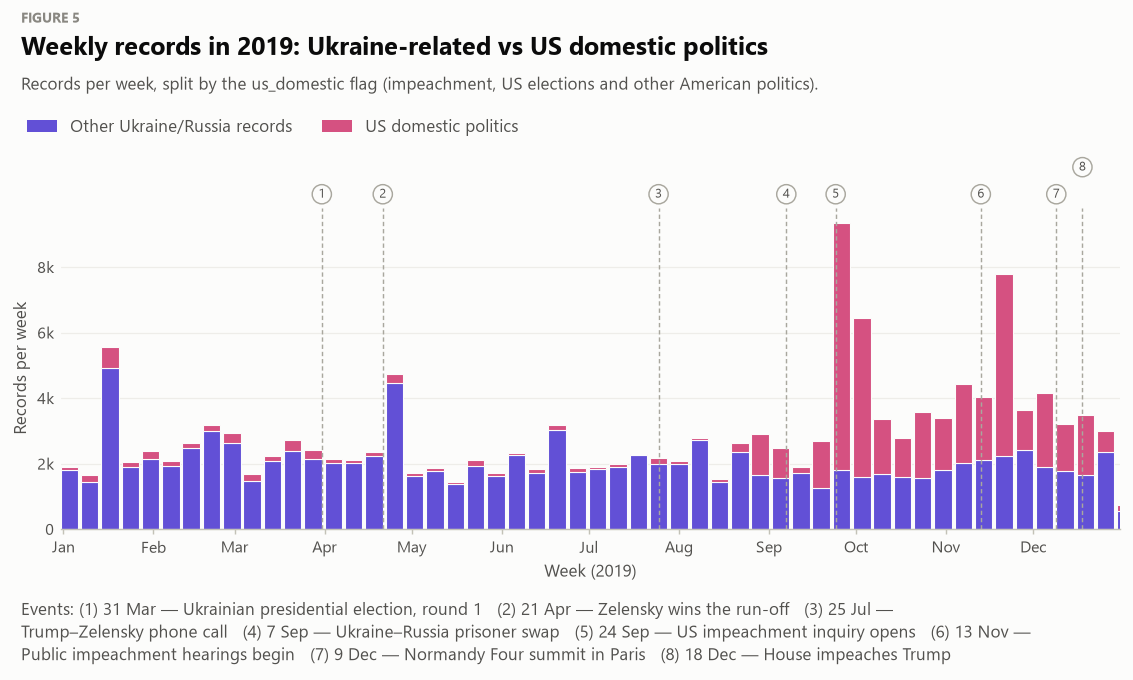

In [8]:
w19 = R[R["year"] == 2019].groupby(["week", "usd"]).size().unstack(fill_value=0).reindex(columns=[0, 1], fill_value=0)
FIGREF["usd2019"] = FIG["n"] + 1
fig, ax = frame("Weekly records in 2019: Ukraine-related vs US domestic politics",
                "Records per week, split by the us_domestic flag (impeachment, US elections and other American politics).",
                h=3.9, note=event_key(EV2019),
                legend=([patch_h(VIOLET), patch_h(PINK)], ["Other Ukraine/Russia records", "US domestic politics"]))
ax.bar(w19.index, w19[0], width=6, align="edge", color=VIOLET, edgecolor=SURFACE, linewidth=0.6)
ax.bar(w19.index, w19[1], bottom=w19[0], width=6, align="edge", color=PINK, edgecolor=SURFACE, linewidth=0.6)
ax.set_xlim(pd.Timestamp("2018-12-31"), pd.Timestamp("2019-12-31"))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.yaxis.set_major_formatter(FuncFormatter(human))
ax.set_ylabel("Records per week")
ax.set_xlabel("Week (2019)")
mark_events(ax, EV2019)
plt.show()

x19 = R[R["year"] == 2019]
late = x19[x19["date"] >= "2019-09-24"]["usd"].mean()
early = x19[x19["date"] < "2019-07-25"]["usd"].mean()
FACTS.update(usd_2019=x19["usd"].mean(), usd_2019_late=late, usd_2019_early=early,
             usd_war=R[R["period"] == "2022_war"]["usd"].mean())
say(f"{FACTS['usd_2019']:.0%} of all 2019 records are flagged as US domestic politics "
    f"(vs {FACTS['usd_war']:.1%} after the invasion).",
    f"Before the Trump–Zelensky call (Jan – 24 Jul) the share is {early:.0%}; from the impeachment inquiry "
    f"(24 Sep) to the end of the year it is **{late:.0%}**.",
    f"This is why all content and tone analysis below uses core records only: otherwise 2019 'Ukraine discussion' "
    f"would mostly measure the American impeachment debate.")

**What we see.** Until September the bars are almost all purple. From late September to December a big pink part appears.

**What it means.** In autumn 2019 a large part of the talk about Ukraine was really about American politics — the Trump–Zelensky call and the impeachment. That is why we leave these records out when we study content and tone.

### 2.4 Where did the conversation happen? (Q3)

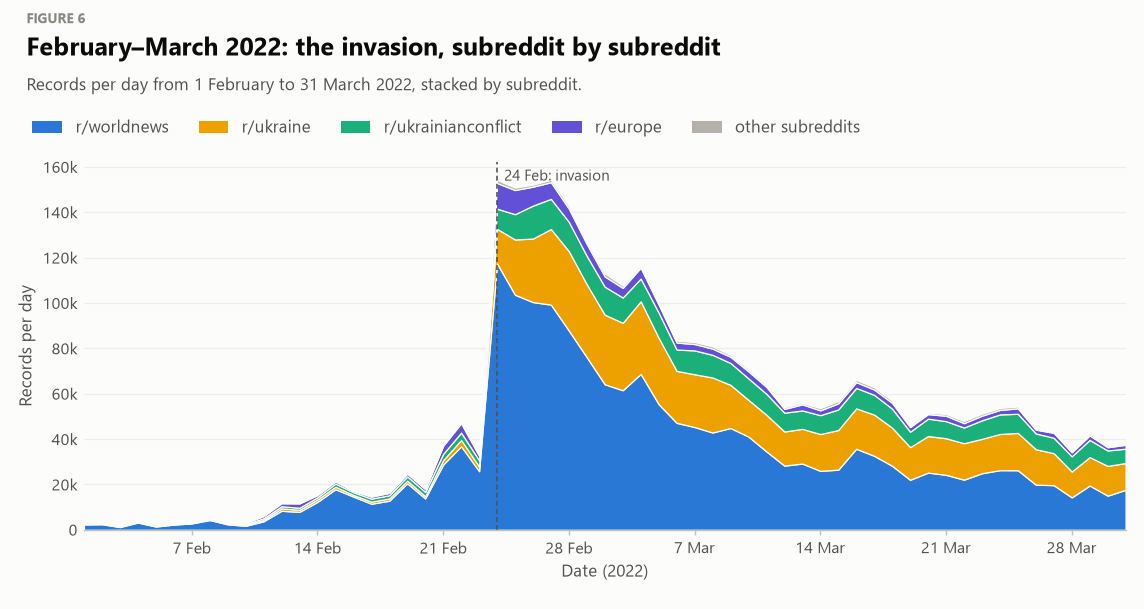

In [9]:
z = R[(R["date"] >= "2022-02-01") & (R["date"] <= "2022-03-31")]
top4 = [s for s in SUB_ORDER if s in set(z["sub"].value_counts().index[:4])][:4]
lab = np.where(z["sub"].isin(top4), z["sub"].astype(str), "other")
piv = z.assign(s=lab).groupby(["date", "s"]).size().unstack(fill_value=0)
cols = top4 + (["other"] if "other" in piv else [])
fig, ax = frame("February–March 2022: the invasion, subreddit by subreddit",
                "Records per day from 1 February to 31 March 2022, stacked by subreddit.",
                h=3.9, legend=([patch_h(SUB_COLOR.get(c, OTHER)) for c in cols],
                               [f"r/{c}" if c != "other" else "other subreddits" for c in cols]))
ax.stackplot(piv.index, [piv[c].to_numpy() for c in cols], colors=[SUB_COLOR.get(c, OTHER) for c in cols],
             edgecolor=SURFACE, linewidth=0.7)
ax.axvline(INVASION, color=INK2, lw=0.9, ls=(0, (3, 2)))
ax.annotate("24 Feb: invasion", xy=(INVASION, 1), xycoords=("data", "axes fraction"), xytext=(4, -4),
            textcoords="offset points", fontsize=8.5, color=INK2, va="top")
ax.set_xlim(piv.index.min(), piv.index.max())
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: day_month(mdates.num2date(v))))
ax.yaxis.set_major_formatter(FuncFormatter(human))
ax.set_ylabel("Records per day")
ax.set_xlabel("Date (2022)")
plt.show()

pre = z[z["date"] < INVASION]["sub"].value_counts(normalize=True)
post = z[z["date"] >= INVASION]["sub"].value_counts(normalize=True)
days_pre, days_post = (INVASION - pd.Timestamp("2022-02-01")).days, (pd.Timestamp("2022-03-31") - INVASION).days + 1
gain = (z[z["date"] >= INVASION]["sub"].value_counts() / days_post) / (z[z["date"] < INVASION]["sub"].value_counts() / days_pre)
say(*[f"r/{s}: {pre.get(s, 0):.0%} of records before 24 Feb → {post.get(s, 0):.0%} after"
      + (f" (×{gain[s]:.0f} records per day)" if np.isfinite(gain.get(s, np.nan)) else "") + "."
      for s in top4])

**What we see.** Activity starts to grow in mid-February and jumps on 24 February in every subreddit. r/worldnews is the biggest layer, but the yellow r/ukraine layer grows the most.

**What it means.** At the start of the war people first went to general news, but very soon many of them moved to the Ukrainian subreddit to follow the war more closely.

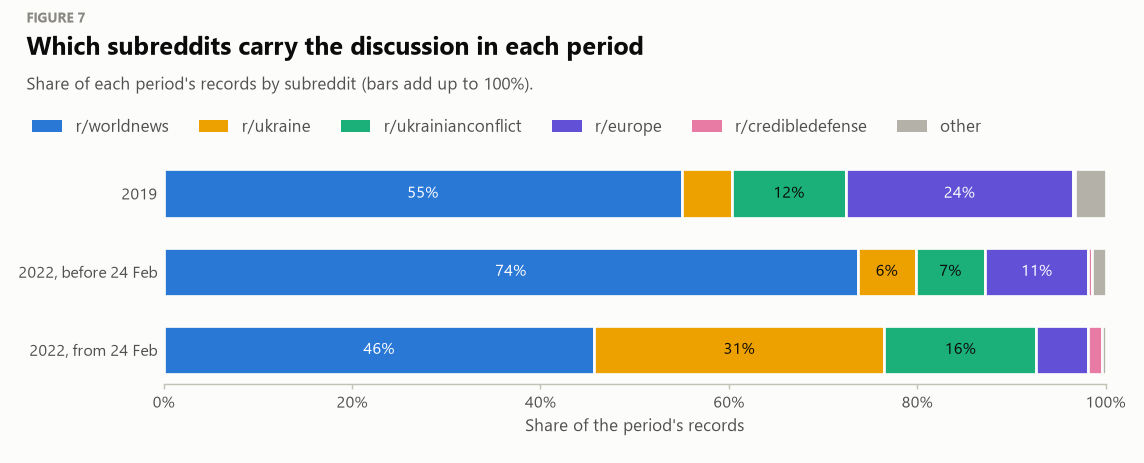

In [10]:
comp = R.groupby(["period", "sub"], observed=True).size().unstack(fill_value=0)
top5 = SUB_ORDER[:5]
comp = comp.reindex(columns=SUB_ORDER, fill_value=0)
comp = pd.concat([comp[top5], comp.drop(columns=top5).sum(axis=1).rename("other")], axis=1)
share = comp.div(comp.sum(axis=1), axis=0) * 100
allsh = R.groupby(["period", "sub"], observed=True).size().unstack(fill_value=0)
allsh = allsh.div(allsh.sum(axis=1), axis=0) * 100
ded = allsh.reindex(columns=["ukraine", "ukrainianconflict", "ukrainewarreport"], fill_value=0).sum(axis=1)
fig, ax = frame("Which subreddits carry the discussion in each period",
                "Share of each period's records by subreddit (bars add up to 100%).",
                h=2.6, legend=([patch_h(SUB_COLOR.get(c, OTHER)) for c in share.columns],
                               [f"r/{c}" if c != "other" else "other" for c in share.columns]), legend_cols=6)
ylab = [PERIOD_LABEL[p] for p in share.index]
left = np.zeros(len(share))
for c in share.columns:
    v = share[c].to_numpy()
    color = SUB_COLOR.get(c, OTHER)
    ax.barh(ylab, v, left=left, color=color, edgecolor=SURFACE, linewidth=1.5, height=0.62)
    for i, (l, w_) in enumerate(zip(left, v)):
        if w_ >= 6:
            dark = color in (BLUE, PINK, VIOLET, GREEN)
            ax.text(l + w_ / 2, i, f"{w_:.0f}%", ha="center", va="center", fontsize=8.6,
                    color="white" if dark else INK)
    left += v
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(pct_fmt())
ax.grid(False)
ax.set_xlabel("Share of the period's records")
plt.show()
say(*[f"{PERIOD_LABEL[p]}: the largest subreddit is r/{share.loc[p].drop('other').idxmax()} "
      f"({share.loc[p].drop('other').max():.0f}% of records)." for p in share.index],
    f"War-dedicated communities (r/ukraine, r/UkrainianConflict, r/UkraineWarReport) hold "
    f"{ded.get('2019', 0):.0f}% of records in 2019, {ded.get('2022_pre', 0):.0f}% before the invasion and "
    f"{ded.get('2022_war', 0):.0f}% after it; r/worldnews {share.get('worldnews', pd.Series()).get('2019', np.nan):.0f}% → "
    f"{share.get('worldnews', pd.Series()).get('2022_war', np.nan):.0f}%.")

**What we see.** Before the invasion r/worldnews holds most of the records. After 24 February its part becomes smaller, and the war subreddits (r/ukraine and r/UkrainianConflict) together take almost half.

**What it means.** The discussion moved from general news to communities dedicated to the war.

How long did each community stay engaged? The heatmap scales every subreddit to its own busiest week (= 100%), so communities of very different size can be compared on one picture.

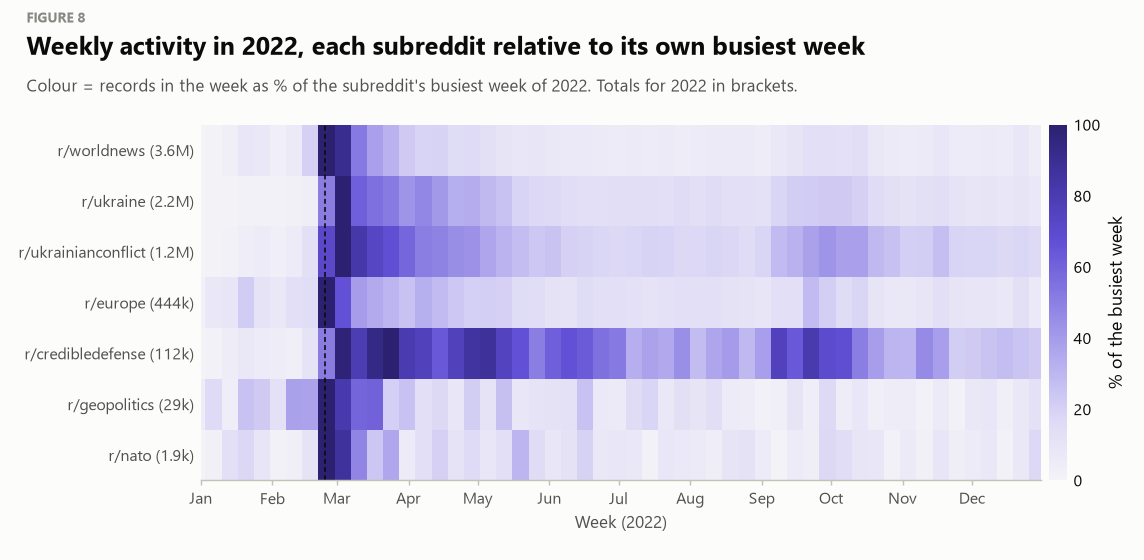

In [11]:
x = R[R["year"] == 2022]
wk = x.groupby(["week", "sub"], observed=True).size().unstack(fill_value=0)
keep = [s for s in SUB_ORDER if s in wk.columns and wk[s].sum() >= 1000]
wk = wk[keep]
normw = wk / wk.max()
fig, ax = frame("Weekly activity in 2022, each subreddit relative to its own busiest week",
                "Colour = records in the week as % of the subreddit's busiest week of 2022. Totals for 2022 in brackets.",
                h=0.42 * len(keep) + 0.9)
x0, x1 = mdates.date2num(wk.index.min()), mdates.date2num(wk.index.max() + pd.Timedelta(days=7))
im = ax.imshow(normw.T.to_numpy() * 100, aspect="auto", cmap=SEQ_VIOLET, vmin=0, vmax=100, interpolation="nearest",
               extent=[x0, x1, len(keep) - 0.5, -0.5])
ax.xaxis_date()
month_axis(ax)
ax.set_yticks(range(len(keep)), [f"r/{s} ({human(wk[s].sum())})" for s in keep])
ax.grid(False)
ax.axvline(INVASION, color=INK, lw=0.9, ls=(0, (3, 2)))
ax.set_xlabel("Week (2022)")
cb = heat_colorbar(ax, im, "% of the busiest week", fraction=0.025)
plt.show()

rows = []
for s in keep:
    v = wk[s]
    p = v.idxmax()
    later = v[p:]
    below = later[later < v.max() / 2]
    rows.append(f"r/{s}: peak in the week of {day_month(p)}; " +
                (f"below half of the peak after {(below.index[0] - p).days // 7} weeks; " if len(below) else "") +
                f"December weeks average {v.loc['2022-12'].mean() / v.max():.0%} of the peak.")
say(*rows)

**What we see.** All rows are darkest around the end of February and become light soon after. Only r/CredibleDefense stays dark for months and has new dark spots in autumn.

**What it means.** Most communities lost interest after the first weeks. The military-analysis community kept following the war, especially during the Ukrainian counteroffensives.

### 2.5 Why each record is in the dataset

`topic_source` tells which rule admitted a record: its text names Ukraine; it names Russia together with an aggression term; it is a comment in an on-topic thread; or it comes from a war-dedicated subreddit. The mix shows whether the *kind* of conversation changed: inside war threads and dedicated communities people no longer need to repeat the word "Ukraine", so a growing share of thread- and subreddit-based records means the discussion moved into such spaces.

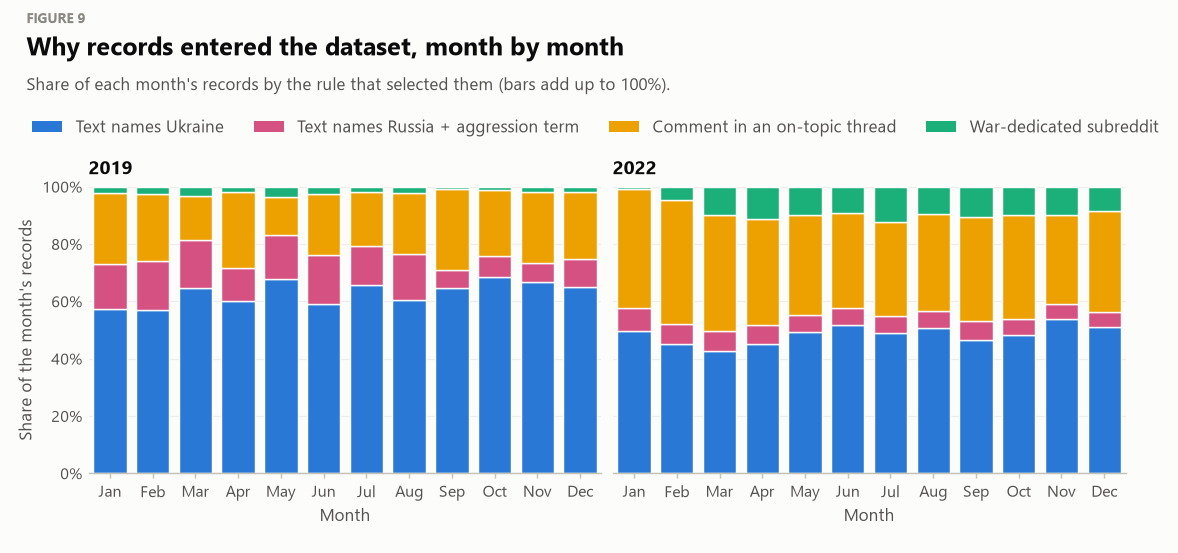

In [12]:
src_order = [s for s in SRC_LABEL if s in set(R["src"].astype(str))]
sm = R.groupby(["year", "mon", "src"], observed=True).size().unstack(fill_value=0).reindex(columns=src_order, fill_value=0)
sm = sm.div(sm.sum(axis=1), axis=0) * 100
fig, axes = frame("Why records entered the dataset, month by month",
                  "Share of each month's records by the rule that selected them (bars add up to 100%).",
                  ncols=2, h=3.4, sharey=True,
                  legend=([patch_h(SRC_COLOR[s]) for s in src_order], [SRC_LABEL[s] for s in src_order]), legend_cols=4)
for ax, y in zip(axes, (2019, 2022)):
    t = sm.loc[y].reindex(range(1, 13)).fillna(0)
    bottom = np.zeros(12)
    for s in src_order:
        ax.bar(t.index, t[s], bottom=bottom, color=SRC_COLOR[s], width=0.78, edgecolor=SURFACE, linewidth=0.8)
        bottom += t[s].to_numpy()
    month_index_axis(ax)
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(pct_fmt())
    ax.set_title(str(y))
    ax.set_xlabel("Month")
axes[0].set_ylabel("Share of the month's records")
plt.show()
sp = R.groupby(["period", "src"], observed=True).size().unstack(fill_value=0)
sp = sp.div(sp.sum(axis=1), axis=0)
say(*[f"{PERIOD_LABEL[p]}: " + ", ".join(f"{SRC_LABEL[s].lower()} {sp.loc[p, s]:.0%}" for s in src_order if s in sp)
      + "." for p in sp.index])

**What we see.** In 2022 the yellow part (comments in on-topic threads) and the green part (war subreddits) are much bigger than in 2019.

**What it means.** In 2022 much of the talk happened inside threads about the war, where people do not need to write the word "Ukraine" — everybody already knows what the thread is about.

### 2.6 A weekly rhythm?

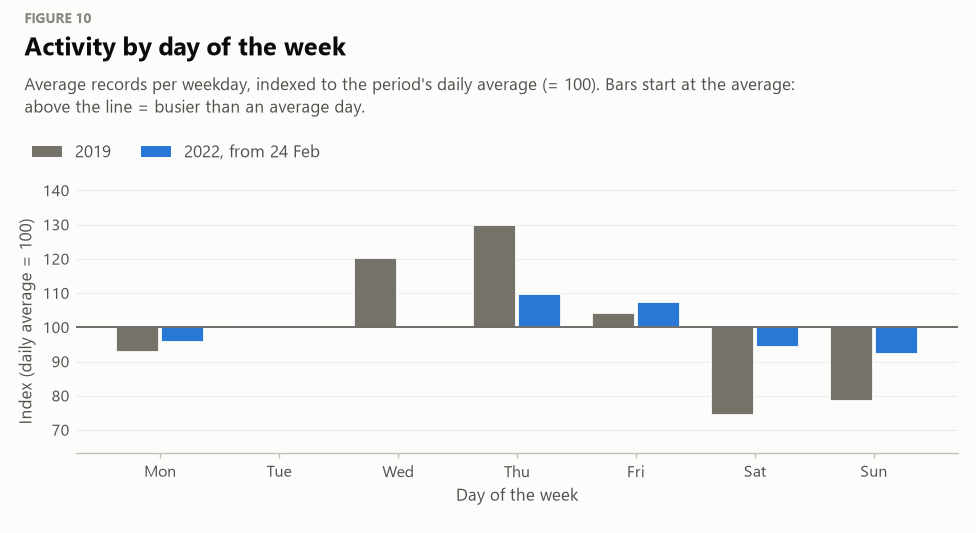

In [13]:
dow = []
for p, (a, b) in {"2019": ("2019-01-01", "2019-12-31"), "2022_war": ("2022-02-24", "2022-12-31")}.items():
    d = R[R["period"] == p].groupby("date").size().reindex(pd.date_range(a, b), fill_value=0)
    v = d.groupby(d.index.dayofweek).mean()
    dow.append((p, v / v.mean() * 100))
fig, ax = frame("Activity by day of the week",
                "Average records per weekday, indexed to the period's daily average (= 100). Bars start at the average: "
                "above the line = busier than an average day.",
                h=3.0, w=8.5, legend=([patch_h(C19), patch_h(BLUE)], ["2019", "2022, from 24 Feb"]))
xs = np.arange(7)
for k, (p, v) in enumerate(dow):
    ax.bar(xs + (k - 0.5) * 0.38, v.to_numpy() - 100, bottom=100, width=0.36, color=PERIOD_COLOR[p],
           edgecolor=SURFACE, linewidth=1)
ax.axhline(100, color=INK2, lw=0.9)
ax.set_xticks(xs, ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_ylim(min(v.min() for _, v in dow) * 0.85, max(v.max() for _, v in dow) * 1.08)
ax.set_ylabel("Index (daily average = 100)")
ax.set_xlabel("Day of the week")
plt.show()
d19v, d22v = dow[0][1], dow[1][1]
say(f"2019: weekends are {100 - d19v[[5, 6]].mean():.0f}% below the average day; "
    f"2022 war: {100 - d22v[[5, 6]].mean():.0f}% below.",
    "A flatter wartime profile means the conversation was driven by news flow rather than by the office-hours "
    "browsing rhythm typical of Reddit." if (100 - d22v[[5, 6]].mean()) < (100 - d19v[[5, 6]].mean())
    else "The weekly rhythm is similar in both years: people read about the war at the same times they use Reddit anyway.")

**What we see.** In 2019 Saturday and Sunday are much lower than the other days. In 2022 the difference between weekdays and weekends is small.

**What it means.** During the war people followed the news every day, not only on working days.

## 3. Structure: threads, scores, length and authors (Q4)

### 3.1 Megathreads

During the war the big subreddits moved most of the minute-by-minute discussion into daily "live threads". If that is true, a tiny fraction of threads should hold a large part of all records.

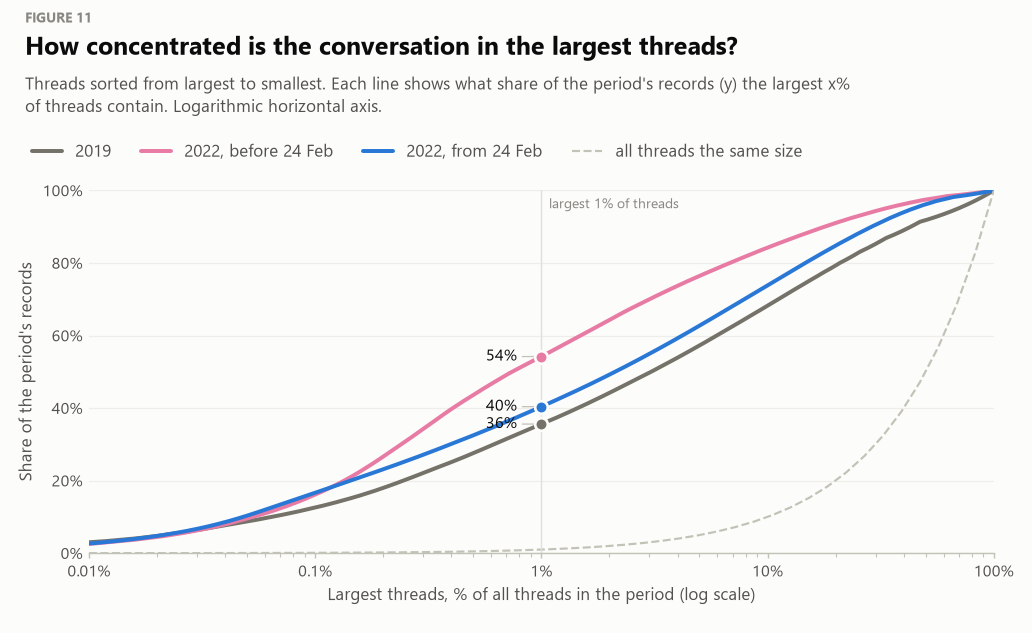

In [14]:
FIGREF["lorenz"] = FIG["n"] + 1
fig, ax = frame("How concentrated is the conversation in the largest threads?",
                "Threads sorted from largest to smallest. Each line shows what share of the period's records (y) "
                "the largest x% of threads contain. Logarithmic horizontal axis.",
                h=3.9, w=9, legend=([line_h(PERIOD_COLOR[p]) for p in PERIODS] + [line_h(AXIS, lw=1.2, ls="--")],
                                    [PERIOD_LABEL[p] for p in PERIODS] + ["all threads the same size"]))
conc = {}
for p in PERIODS:
    t = R[R["period"] == p].groupby("thread").size()
    sizes = np.sort(t.to_numpy())[::-1]
    if len(sizes) == 0:
        continue
    cum_rec = np.cumsum(sizes) / sizes.sum() * 100
    cum_thr = np.arange(1, len(sizes) + 1) / len(sizes) * 100
    idx = np.unique(np.geomspace(1, len(sizes), 500).astype(int)) - 1
    ax.plot(cum_thr[idx], cum_rec[idx], color=PERIOD_COLOR[p], lw=2.2)
    k = max(int(round(len(sizes) * 0.01)), 1)
    ax.plot(cum_thr[k - 1], cum_rec[k - 1], "o", color=PERIOD_COLOR[p], ms=7, mec=SURFACE, mew=1.5, zorder=4)
    big = t.idxmax()
    first = R.loc[R["thread"] == big, ["sub", "date"]]
    conc[p] = dict(top1=cum_rec[k - 1], threads=len(sizes), largest=int(sizes[0]),
                   largest_sub=str(first["sub"].mode().iloc[0]), largest_date=first["date"].min(),
                   median=float(np.median(sizes)))
labs = [(p, c["top1"]) for p, c in conc.items()]
for (p, y0), yl in zip(labs, spread([y for _, y in labs], 4.5)):
    ax.annotate(f"{y0:.0f}%", xy=(1, y0), xytext=(0.78, yl), textcoords="data", ha="right", va="center",
                fontsize=8.6, color=INK, arrowprops=dict(arrowstyle="-", color=AXIS, lw=0.7, shrinkA=1, shrinkB=4))
ax.text(1.08, 98, "largest 1% of threads", fontsize=8, color=MUTED, va="top")
xx = np.geomspace(0.01, 100, 50)
ax.plot(xx, xx, color=AXIS, lw=1.2, ls="--")
ax.set_xscale("log")
ax.set_xlim(0.01, 100)
ax.set_ylim(0, 100)
ax.set_xticks([0.01, 0.1, 1, 10, 100], ["0.01%", "0.1%", "1%", "10%", "100%"])
ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, p: ""))
ax.yaxis.set_major_formatter(pct_fmt())
ax.axvline(1, color=GRID, lw=0.8)
ax.set_xlabel("Largest threads, % of all threads in the period (log scale)")
ax.set_ylabel("Share of the period's records")
plt.show()
FACTS["conc"] = conc
say(*[f"{PERIOD_LABEL[p]}: {c['threads']:,} threads; the largest 1% hold **{c['top1']:.0f}%** of records; "
      f"the biggest thread (r/{c['largest_sub']}, started {c['largest_date']:%d %b %Y}) has {c['largest']:,} records."
      for p, c in conc.items()])

**What we see.** All lines rise steeply on the left: a small number of big threads holds a large part of all records. The pink line (before the invasion) is the highest.

**What it means.** Discussion on Reddit gathers in a few big threads. Just before the invasion this was the strongest: the talk about a possible war was collected in a few huge threads.

### 3.2 Scores of submissions and comments

Reddit's `score` is upvotes minus downvotes. Submissions and comments live on completely different scales, so they are shown separately.

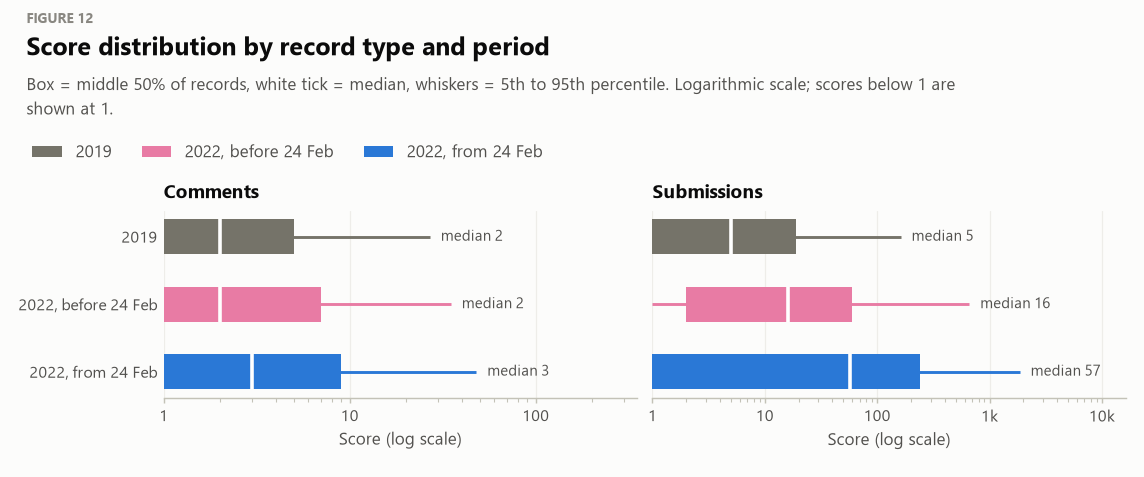

In [15]:
fig, axes = frame("Score distribution by record type and period",
                  "Box = middle 50% of records, white tick = median, whiskers = 5th to 95th percentile. "
                  "Logarithmic scale; scores below 1 are shown at 1.",
                  ncols=2, h=2.5, sharey=True, legend=period_legend("patch"))
score_stats = {}
for ax, t, name in zip(axes, ["comment", "submission"], ["Comments", "Submissions"]):
    for i, p in enumerate(PERIODS):
        v = R.loc[(R["type"] == t) & (R["period"] == p), "score"].to_numpy()
        if len(v) == 0:
            continue
        q = np.percentile(np.clip(v, 1, None), [5, 25, 50, 75, 95])
        y = len(PERIODS) - 1 - i
        c = PERIOD_COLOR[p]
        ax.hlines(y, q[0], q[4], color=c, lw=1.6)
        ax.barh(y, max(q[3] - q[1], q[1] * 0.04), left=q[1], height=0.52, color=c)
        ax.vlines(q[2], y - 0.26, y + 0.26, color="white", lw=2)
        ax.annotate(f"median {np.median(v):,.0f}", xy=(q[4], y), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=8.3, color=INK2)
        score_stats[(t, p)] = dict(median=float(np.median(v)), p95=float(np.percentile(v, 95)), le1=float((v <= 1).mean()))
    ax.set_xscale("log")
    ax.set_title(name)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Score (log scale)")
    ax.xaxis.set_major_formatter(FuncFormatter(human))
    lo_, hi_ = ax.get_xlim()
    ax.set_xlim(1, hi_ * 6)
axes[0].set_yticks(range(len(PERIODS)), [PERIOD_LABEL[p] for p in PERIODS][::-1])
plt.show()
say(*[f"{t.capitalize()}s, {PERIOD_LABEL[p]}: median score {s['median']:,.0f}, 95th percentile {s['p95']:,.0f}, "
      f"{s['le1']:.0%} have a score of 1 or less." for (t, p), s in score_stats.items()],
    (lambda a, b: f"The median wartime submission scores {a:,.0f} vs {b:,.0f} in 2019: "
     + ("the same subreddits suddenly had many more readers voting." if a > b * 1.2 else
        "scores did not grow with volume — more posts competed for the same attention."))(
        score_stats.get(("submission", "2022_war"), {}).get("median", np.nan),
        score_stats.get(("submission", "2019"), {}).get("median", np.nan)))

**What we see.** The blue boxes (2022, after the invasion) are further to the right, especially for posts.

**What it means.** Posts about Ukraine got many more upvotes during the war — far more people were reading and voting.

### 3.3 Text length

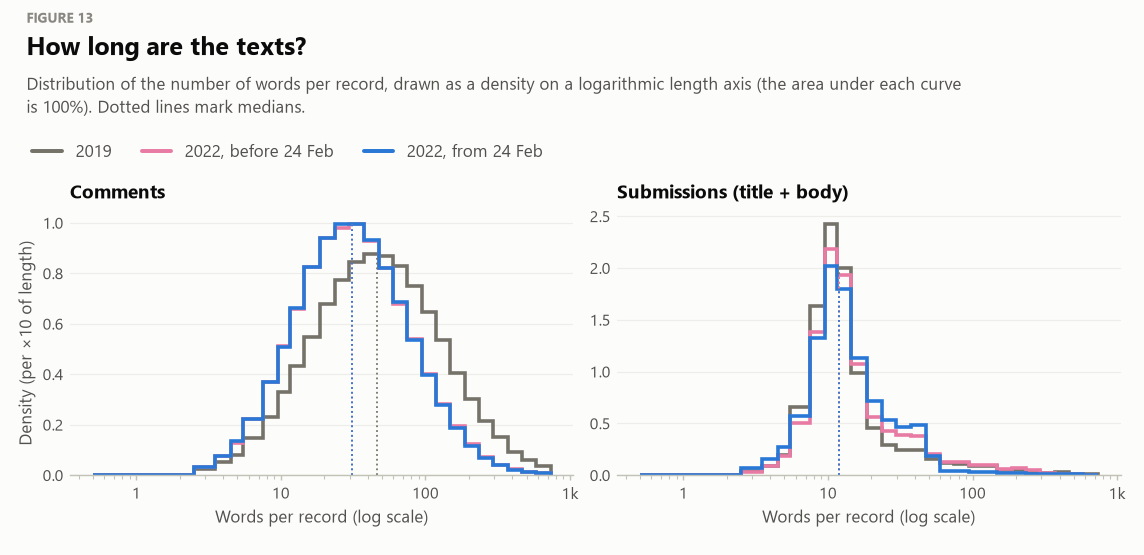

In [16]:
bins = np.unique(np.round(np.geomspace(max(R["nw"].min(), 1), max(R["nw"].quantile(0.999), 50), 30))) - 0.5
fig, axes = frame("How long are the texts?",
                  "Distribution of the number of words per record, drawn as a density on a logarithmic length axis "
                  "(the area under each curve is 100%). Dotted lines mark medians.",
                  ncols=2, h=3.2, sharex=True, legend=period_legend("line"))
len_stats = {}
for ax, t, name in zip(axes, ["comment", "submission"], ["Comments", "Submissions (title + body)"]):
    for p in PERIODS:
        v = R.loc[(R["type"] == t) & (R["period"] == p), "nw"].to_numpy()
        if len(v) == 0:
            continue
        h, _ = np.histogram(v, bins)
        h = h / max(h.sum(), 1) / np.diff(np.log10(bins))
        ax.stairs(h, bins, color=PERIOD_COLOR[p], lw=2)
        med = np.median(v)
        hb = h[min(np.searchsorted(bins, med) - 1, len(h) - 1)]
        ax.vlines(med, 0, hb, color=PERIOD_COLOR[p], lw=1, ls=":")
        len_stats[(t, p)] = med
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(FuncFormatter(human))
    ax.set_title(name)
    ax.set_xlabel("Words per record (log scale)")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.1f}"))
axes[0].set_ylabel("Density (per ×10 of length)")
plt.show()
say(*[f"Median length of {t}s: " + ", ".join(f"{PERIOD_LABEL[p]} {len_stats[(t, p)]:.0f} words" for p in PERIODS
                                              if (t, p) in len_stats) + "." for t in ("comment", "submission")],
    "The left edge is a filter artefact: texts shorter than the minimum length were dropped in Homework #2.")

**What we see.** For comments, the 2022 curves are shifted to the left of the grey 2019 curve. For posts the curves almost match.

**What it means.** Comments became shorter during the war: fast news brings short, quick reactions.

### 3.4 Who is talking? Author countries

`author_country` is known only when the author's flair or text reveals it ("As a Pole…"), so it covers a small minority of records and is biased towards people who want their nationality to be seen. It is still useful as a rough picture.

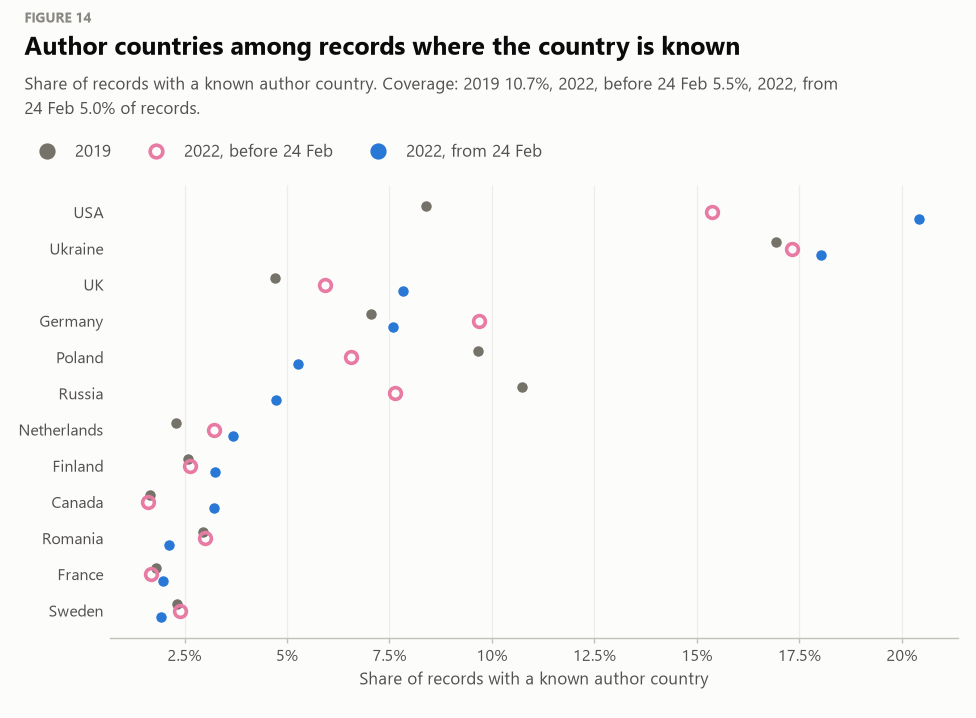

In [17]:
known = R[R["auth"] != "(unknown)"]
cov = R.groupby("period", observed=True)["auth"].apply(lambda s: (s != "(unknown)").mean())
topc = known["auth"].value_counts().index[:12].tolist()
sh = known.groupby(["period", "auth"], observed=True).size().unstack(fill_value=0)
sh = sh.div(sh.sum(axis=1), axis=0).reindex(columns=topc) * 100
order_c = sh.loc["2022_war"].sort_values().index if "2022_war" in sh.index else topc
fig, ax = frame("Author countries among records where the country is known",
                f"Share of records with a known author country. Coverage: " +
                ", ".join(f"{PERIOD_LABEL[p]} {cov.get(p, 0):.1%}" for p in PERIODS) + " of records.",
                h=0.33 * len(order_c) + 0.7, w=8.5,
                legend=period_legend())
for i, c in enumerate(order_c):
    vals = [sh.loc[p, c] if p in sh.index else np.nan for p in PERIODS]
    for p, v, dy in zip(PERIODS, vals, (0.18, 0, -0.18)):
        period_dot(ax, v, i + dy, p, ms=7)
ax.set_yticks(range(len(order_c)), order_c)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(pct_fmt())
ax.set_xlabel("Share of records with a known author country")
plt.show()
w_ = sh.loc["2022_war"].sort_values(ascending=False) if "2022_war" in sh.index else sh.iloc[-1]
say(f"Only {(R['auth'] != '(unknown)').mean():.1%} of records reveal the author's country, so these shares are indicative.",
    f"After the invasion the most visible author countries are " +
    ", ".join(f"{c} ({v:.0f}%)" for c, v in w_.head(4).items()) + ".")

**What we see.** After the invasion the most visible author countries are the USA and Ukraine, then the UK and Germany. Russia and Poland are less visible than in 2019.

**What it means.** Mostly Americans and Ukrainians wrote about the war. This is only a rough picture, because few users show their country.

## 4. Content: who and what is discussed

From here on we use **core records** only (US-domestic and lifestyle records excluded) and compare periods through rates.

### 4.1 Faces of the conversation

Mentions of four leaders by name in the full text (all records, including US-domestic ones, because the 2019 story is about Trump).

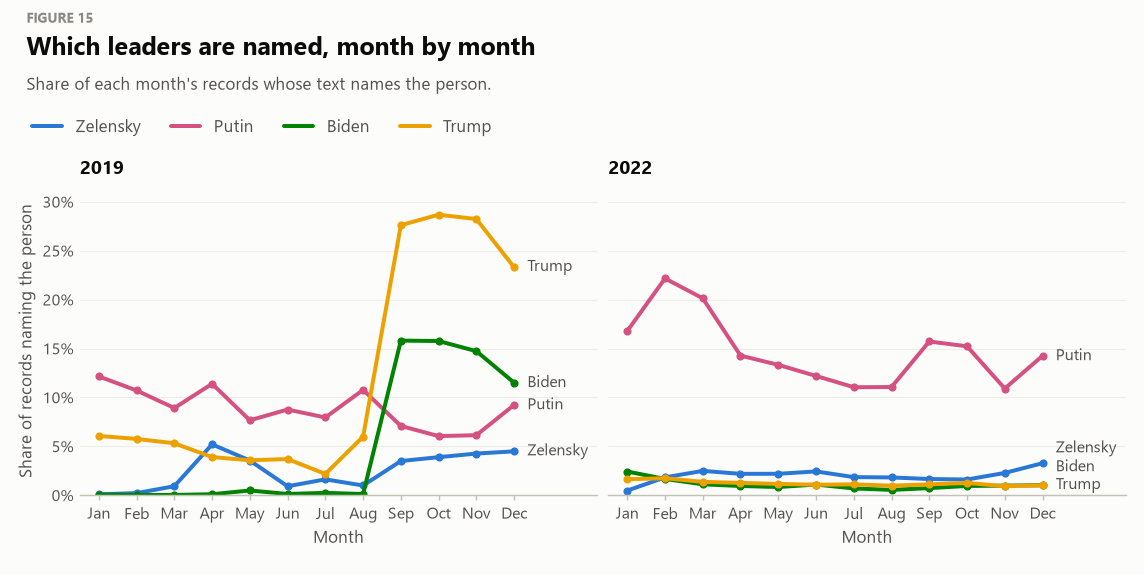

In [18]:
lm = R.groupby(["year", "mon"])[[f"kw_{k}" for k in LEADERS]].mean() * 100
FIGREF["leaders"] = FIG["n"] + 1
fig, axes = frame("Which leaders are named, month by month",
                  "Share of each month's records whose text names the person.",
                  ncols=2, h=3.6, sharey=True,
                  legend=([line_h(c) for _, c in LEADERS.values()], [n for n, _ in LEADERS.values()]))
for ax, y in zip(axes, (2019, 2022)):
    t = lm.loc[y].reindex(range(1, 13))
    for k, (name, c) in LEADERS.items():
        ax.plot(t.index, t[f"kw_{k}"], color=c, lw=2.2, marker="o", ms=3.5)
    month_index_axis(ax)
    ax.set_xlim(0.5, 14.2)
    ax.set_title(str(y))
    ax.set_xlabel("Month")
    ax.set_ylim(bottom=0)
axes[1].set_ylim(0, lm.max().max() * 1.1)
for ax, y in zip(axes, (2019, 2022)):
    t = lm.loc[y].reindex(range(1, 13))
    last = t.iloc[-1]
    ys = spread(last.to_numpy(), ax.get_ylim()[1] * 0.06)
    for (k, (name, c)), yl in zip(LEADERS.items(), ys):
        ax.text(12.35, yl, name, va="center", fontsize=8.6, color=INK2)
axes[0].yaxis.set_major_formatter(pct_fmt())
axes[0].set_ylabel("Share of records naming the person")
plt.show()
yr = R.groupby("period", observed=True)[[f"kw_{k}" for k in LEADERS]].mean() * 100
FACTS["leaders"] = yr
say(*[f"{PERIOD_LABEL[p]}: " + ", ".join(f"{LEADERS[k][0]} {yr.loc[p, f'kw_{k}']:.1f}%" for k in LEADERS) + "."
      for p in yr.index],
    (f"In 2019 Trump is named more often than Putin ({yr.loc['2019', 'kw_trump']:.0f}% vs {yr.loc['2019', 'kw_putin']:.0f}%) "
     f"— the impeachment again." if yr.loc["2019", "kw_trump"] > yr.loc["2019", "kw_putin"] else
     f"Even in 2019 Putin is named more often than Trump ({yr.loc['2019', 'kw_putin']:.0f}% vs {yr.loc['2019', 'kw_trump']:.0f}%)."),
    f"After the invasion the most named leader is **{LEADERS[yr.loc['2022_war'].idxmax()[3:]][0]}**; the US president "
    f"is named in {yr.loc['2022_war', 'kw_biden']:.1f}% of records.")

**What we see.** In 2019 Trump's line jumps up in September and stays very high until the end of the year. In 2022 Putin's line is far above everybody else all year.

**What it means.** In 2019 Ukraine was discussed through the US impeachment. In 2022 the war is discussed mostly through Putin, the person who started it.

### 4.2 Which countries are discussed? (Q5)

`countries_focus` keeps a country only when it appears **in the same sentence** as Ukraine, a type of support, or Russia with an aggression term — i.e. when the country is part of the Ukraine story, not just mentioned. We measure attention as **mentions per 1,000 core records**, which makes periods of different length comparable.

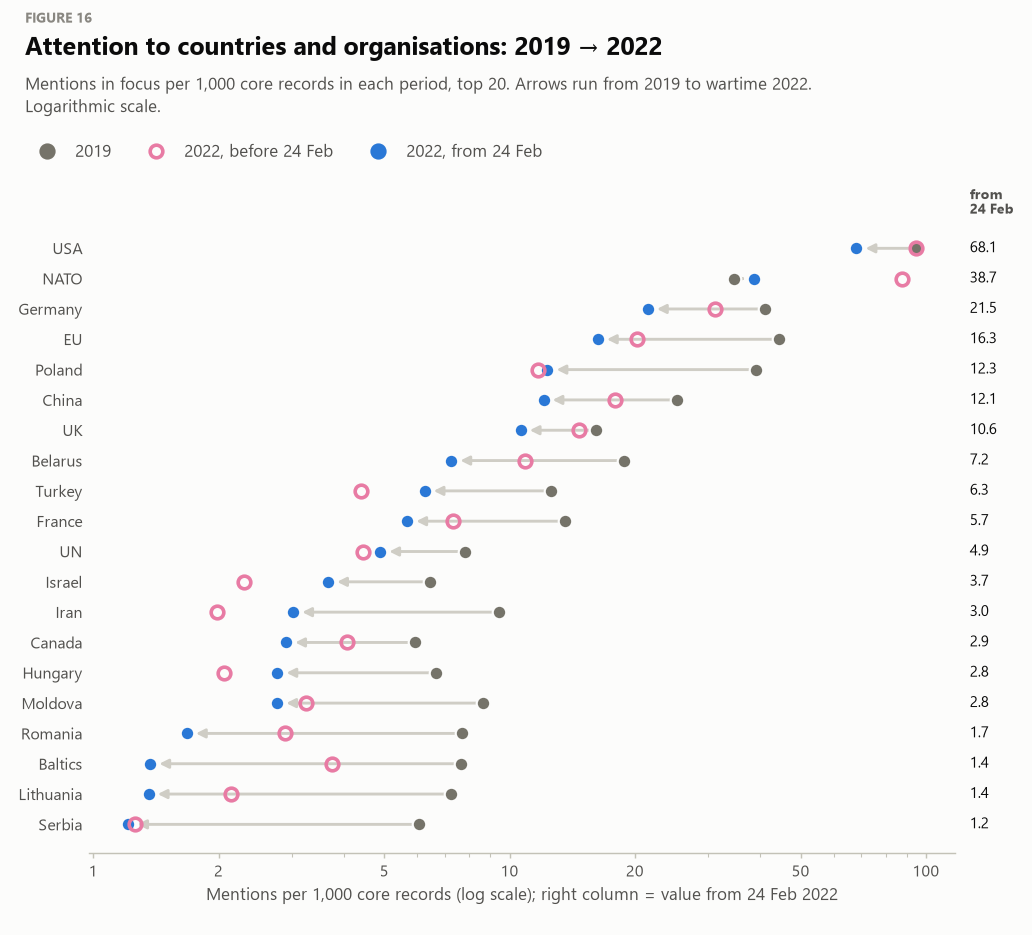

In [19]:
cnt = FOCUS.groupby(["ent", "per"], observed=True).size().unstack(fill_value=0).reindex(columns=[0, 1, 2], fill_value=0)
RATE = cnt / N_CORE.reindex([0, 1, 2]).to_numpy() * 1000
RATE.columns = PERIODS
top20 = RATE.assign(m=RATE.max(axis=1)).nlargest(20, "m").sort_values("2022_war").drop(columns="m")
FIGREF["attention"] = FIG["n"] + 1
fig, ax = frame("Attention to countries and organisations: 2019 → 2022",
                "Mentions in focus per 1,000 core records in each period, top 20. Arrows run from 2019 to wartime 2022. "
                "Logarithmic scale.",
                h=0.3 * len(top20) + 0.6, w=9,
                legend=period_legend())
period_arrows(ax, top20, "{:.1f}", log=True)
ax.set_xscale("log")
log_ticks(ax.xaxis, fmt=lambda v, p: f"{v:g}")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Mentions per 1,000 core records (log scale); right column = value from 24 Feb 2022")
plt.show()
chg = (RATE["2022_war"] / RATE["2019"]).replace([np.inf, -np.inf], np.nan)
chg = chg[(cnt[0] >= 30) & (cnt[2] >= 300)].dropna().sort_values()
FACTS["attention_up"], FACTS["attention_down"] = chg.tail(5), chg.head(5)
say("Mentioned more often than in 2019 (per 1,000 records): "
    + (", ".join(f"{e} ×{v:.1f}" for e, v in chg[chg > 1].sort_values(ascending=False).items()) or "none") + ".",
    f"Biggest drops: " + ", ".join(f"{e} ×{v:.2f}" for e, v in chg.head(5).items()) + ".",
    f"The USA stays the most discussed country in every period ({RATE.loc['USA', '2019']:.0f} → "
    f"{RATE.loc['USA', '2022_war']:.0f} per 1,000 records)." if "USA" in RATE.index else "")

**What we see.** For most countries the blue dot (2022, war) is to the left of the grey dot (2019): they are mentioned less often per 1,000 records. NATO is almost the only one that moved to the right. Before the invasion (pink rings) NATO and the USA are mentioned especially often.

**What it means.** During the war the conversation is mostly about the war itself — battles, weapons, soldiers — so other countries take a smaller part of it. Before the invasion people talked a lot about NATO, because Russia demanded that NATO stop expanding.

**The same on a map.** Attention after the invasion, country by country. Ukraine and Russia stay grey: every record is about them by construction, so they are not counted as "mentions".

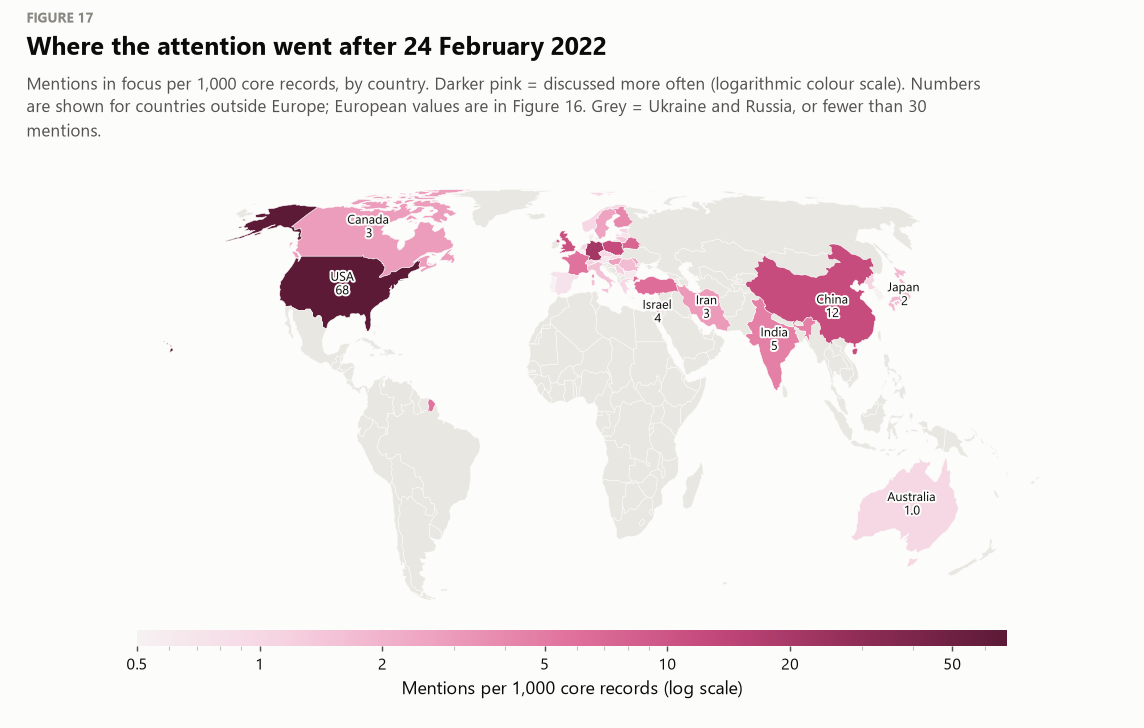

In [20]:
if GEO is None:
    print("Map skipped: eda_assets/countries.json not found next to the notebook.")
else:
    att = RATE["2022_war"].drop([e for e in ORGS if e in RATE.index])
    att = att[(cnt[2].reindex(att.index).fillna(0) >= 30) & (att > 0)]
    lo1, lo2, la1, la2 = EUROPE_VIEW["extent"]
    outside = {f["a3"] for f in GEO["world"] if f["lx"] is not None and not (lo1 <= f["lx"] <= lo2 and la1 <= f["ly"] <= la2)}
    label_pt = {f["a3"]: (f["lx"], f["ly"]) for f in GEO["world"] if f["lx"] is not None}
    labels, placed = {}, []
    for e, v in att.sort_values(ascending=False).items():        # biggest first; skip labels that would collide
        a = ENT_A3.get(e)
        if a not in outside or a not in label_pt:
            continue
        x_, y_ = label_pt[a]
        if all(abs(x_ - px) > 16 or abs(y_ - py) > 9 for px, py in placed):
            labels[a] = f"{e}\n{v:.0f}" if v >= 1 else f"{e}\n{v:.1f}"
            placed.append((x_, y_))
    norm = LogNorm(vmin=max(att.min(), 0.5), vmax=att.max())
    FIGREF["world_map"] = FIG["n"] + 1
    fig, ax = frame("Where the attention went after 24 February 2022",
                    "Mentions in focus per 1,000 core records, by country. Darker pink = discussed more often (logarithmic "
                    "colour scale). Numbers are shown for countries outside Europe; European values are in Figure "
                    f"{FIGREF['attention']}. Grey = Ukraine and Russia, or fewer than 30 mentions.",
                    h=4.9, w=10)
    draw_map(ax, "world", to_a3(att), SEQ_PINK, norm, equal_earth, labels=labels, lw=0.3)
    ticks = [t for t in (0.5, 1, 2, 5, 10, 20, 50, 100, 200, 500) if norm.vmin <= t <= norm.vmax]
    map_colorbar(ax, SEQ_PINK, norm, "Mentions per 1,000 core records (log scale)", ticks=ticks, fmt=lambda t: f"{t:g}")
    plt.show()
    say("Most discussed after the invasion: " + ", ".join(f"{e} ({v:.0f})" for e, v in att.sort_values(ascending=False).head(6).items()) + ".",
        "Outside Europe: " + ", ".join(f"{e} ({att[e]:.1f})" for e in att.sort_values(ascending=False).index
                                       if e in ENT_A3 and ENT_A3[e] in outside and e != "USA")[:400] + ".")

**What we see.** The USA is by far the darkest country. Outside Europe, China, India, Israel and Iran also stand out.

**What it means.** These are the countries whose actions mattered for the war: American help, China's and India's ties with Russia, Iranian drones.

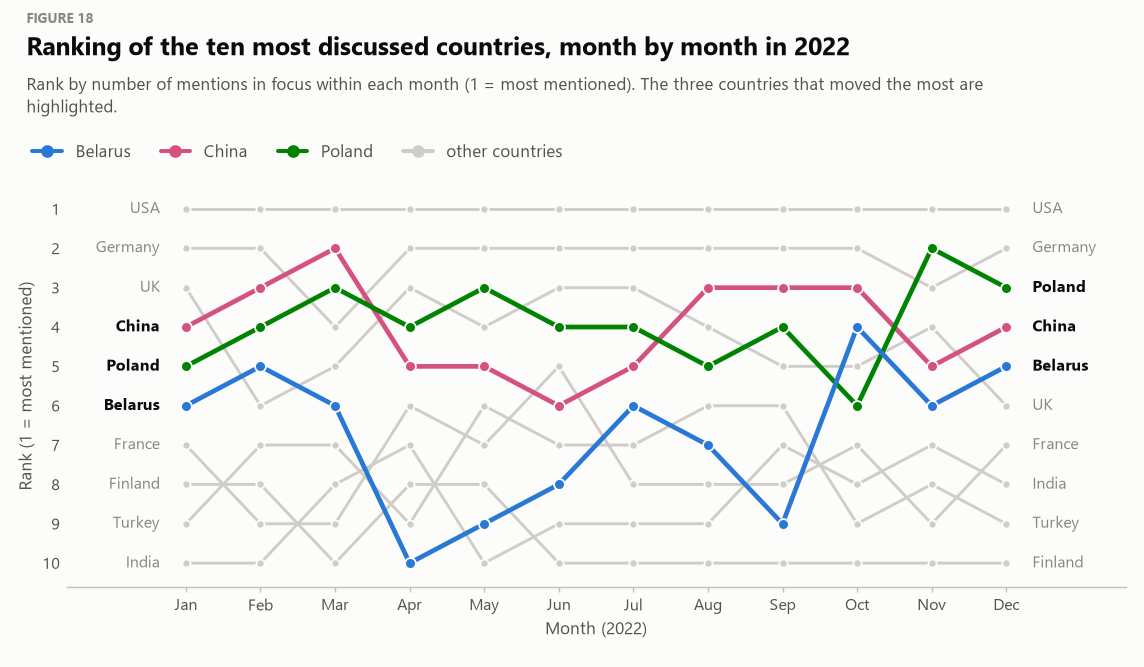

In [21]:
COUNTRIES = [e for e in cnt.sort_values(2, ascending=False).index if e not in ORGS]
F22 = FOCUS[FOCUS["year"] == 2022]
top10 = [e for e in F22["ent"].value_counts().index if e not in ORGS][:10]
mc = F22[F22["ent"].isin(top10)].groupby(["mon", "ent"], observed=True).size().unstack(fill_value=0).reindex(columns=top10, fill_value=0)
rank = mc.rank(axis=1, ascending=False, method="first")
span = (rank.max() - rank.min()).sort_values(ascending=False)
hl = span.index[:3].tolist()
HL_COLOR = dict(zip(hl, [BLUE, PINK, GREEN]))
fig, ax = frame("Ranking of the ten most discussed countries, month by month in 2022",
                "Rank by number of mentions in focus within each month (1 = most mentioned). "
                "The three countries that moved the most are highlighted.",
                h=4.2, w=10, legend=([line_h(HL_COLOR[e], marker="o") for e in hl] + [line_h(CONTEXT, marker="o")],
                                     hl + ["other countries"]))
for e in top10:
    c = HL_COLOR.get(e, CONTEXT)
    lw, z = (2.6, 3) if e in HL_COLOR else (1.6, 2)
    ax.plot(rank.index, rank[e], color=c, lw=lw, marker="o", ms=6 if e in HL_COLOR else 4.5, zorder=z,
            mec=SURFACE, mew=1)
    ax.text(12.35, rank[e].iloc[-1], e, va="center", fontsize=8.8, color=INK if e in HL_COLOR else MUTED,
            weight="bold" if e in HL_COLOR else "normal")
    ax.text(0.65, rank[e].iloc[0], e, va="center", ha="right", fontsize=8.8,
            color=INK if e in HL_COLOR else MUTED, weight="bold" if e in HL_COLOR else "normal")
ax.set_ylim(len(top10) + 0.6, 0.4)
ax.set_yticks(range(1, len(top10) + 1))
ax.set_xticks(range(1, 13), MONTHS)
ax.set_xlim(-0.6, 13.6)
ax.grid(axis="y", visible=False)
ax.set_ylabel("Rank (1 = most mentioned)")
ax.set_xlabel("Month (2022)")
plt.show()
say(*[f"{e}: rank {int(rank[e].min())}–{int(rank[e].max())} during 2022 "
      f"(best in {MONTHS_FULL[int(rank[e].idxmin()) - 1]}, worst in {MONTHS_FULL[int(rank[e].idxmax()) - 1]})."
      for e in hl])

**What we see.** The USA is first every month, but the places below keep changing. China rises to second place in March, Belarus jumps up in October, and Poland rises to second place in November.

**What it means.** The ranking follows the news: reports that Russia asked China for help (March), the joint Russian–Belarusian troops (October) and the missile that fell in Poland (November).

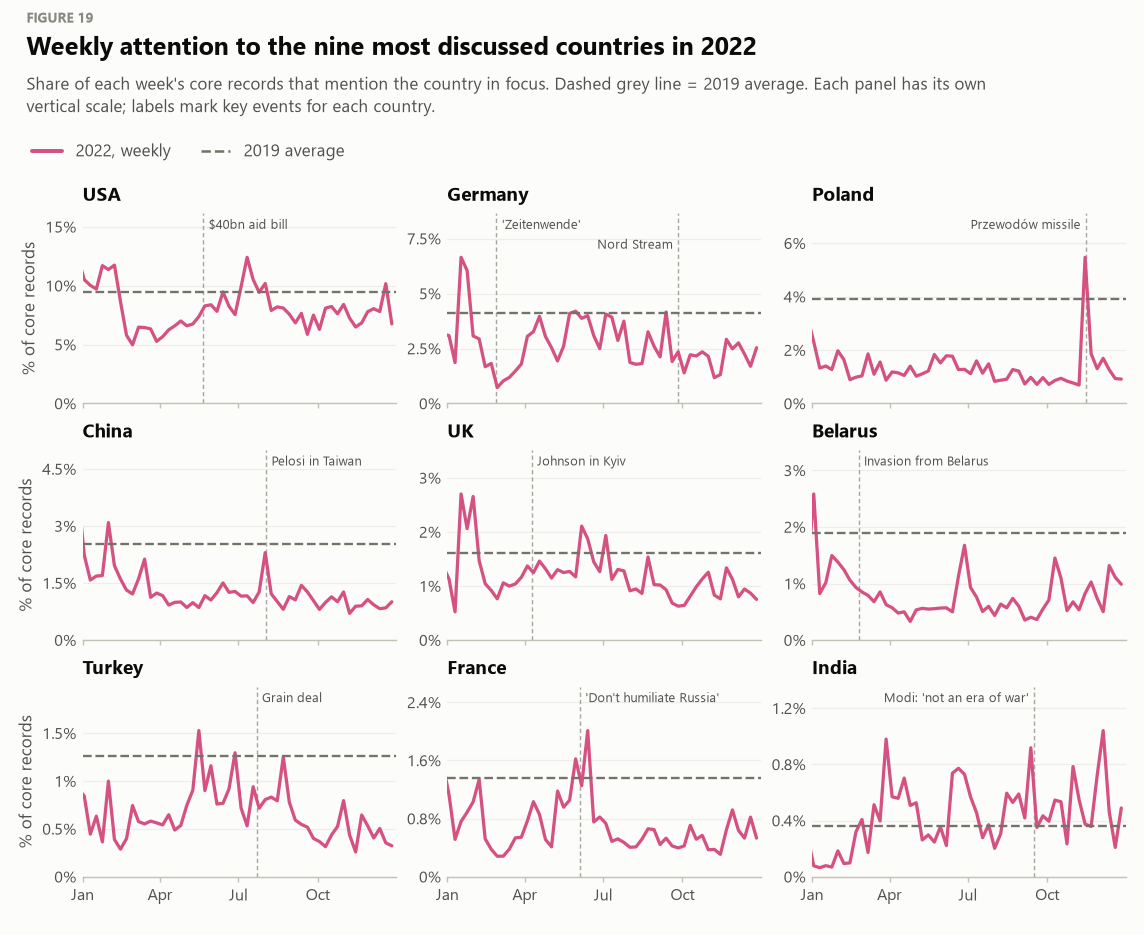

In [22]:
ALLIES9 = [e for e in COUNTRIES if e not in ("Ukraine", "Russia")][:9]
wk_core = CORE[CORE["year"] == 2022].groupby("week").size()
fw = (FOCUS[(FOCUS["year"] == 2022) & FOCUS["ent"].isin(ALLIES9)]
      .assign(week=lambda t: R["week"].to_numpy()[t["row"].to_numpy()])
      .groupby(["week", "ent"], observed=True).size().unstack(fill_value=0).reindex(index=wk_core.index, fill_value=0))
fw = fw.div(wk_core, axis=0) * 100
base19 = RATE["2019"] / 10        # per 1,000 -> %
FIGREF["allies"] = FIG["n"] + 1
fig, axes = frame("Weekly attention to the nine most discussed countries in 2022",
                  "Share of each week's core records that mention the country in focus. Dashed grey line = 2019 average. "
                  "Each panel has its own vertical scale; labels mark key events for each country.",
                  nrows=3, ncols=3, h=6.6, sharex=True,
                  legend=([line_h(PINK), line_h(C19, lw=1.4, ls="--")], ["2022, weekly", "2019 average"]))
weekly_panels(axes, fw, base19, ALLIES9, PINK, events=ENTITY_EVENTS)
plt.show()
peaks = {e: fw[e].idxmax() for e in ALLIES9 if e in fw}
say(*[f"{e}: peak in the week of {day_month(w)} ({fw.loc[w, e]:.1f}% of records)"
      + (f"; 2019 average {base19[e]:.1f}%." if e in base19.index else ".") for e, w in peaks.items()])

**What we see.** Each country has its own short spike: Poland in the week of the missile in Przewodów, Turkey in May, Germany in January, before the invasion. India's line slowly rises during the year.

**What it means.** Countries get attention when they are part of a specific event: Turkey when it blocked Finland's and Sweden's NATO bid, Germany when it refused to send weapons before the invasion. India gets more attention over time, probably because of its neutral position and its purchases of Russian oil.

Which countries are discussed **together**? The lift of a pair is how many times more often two countries appear in the same record than if mentions were independent (lift 1 = no relation).

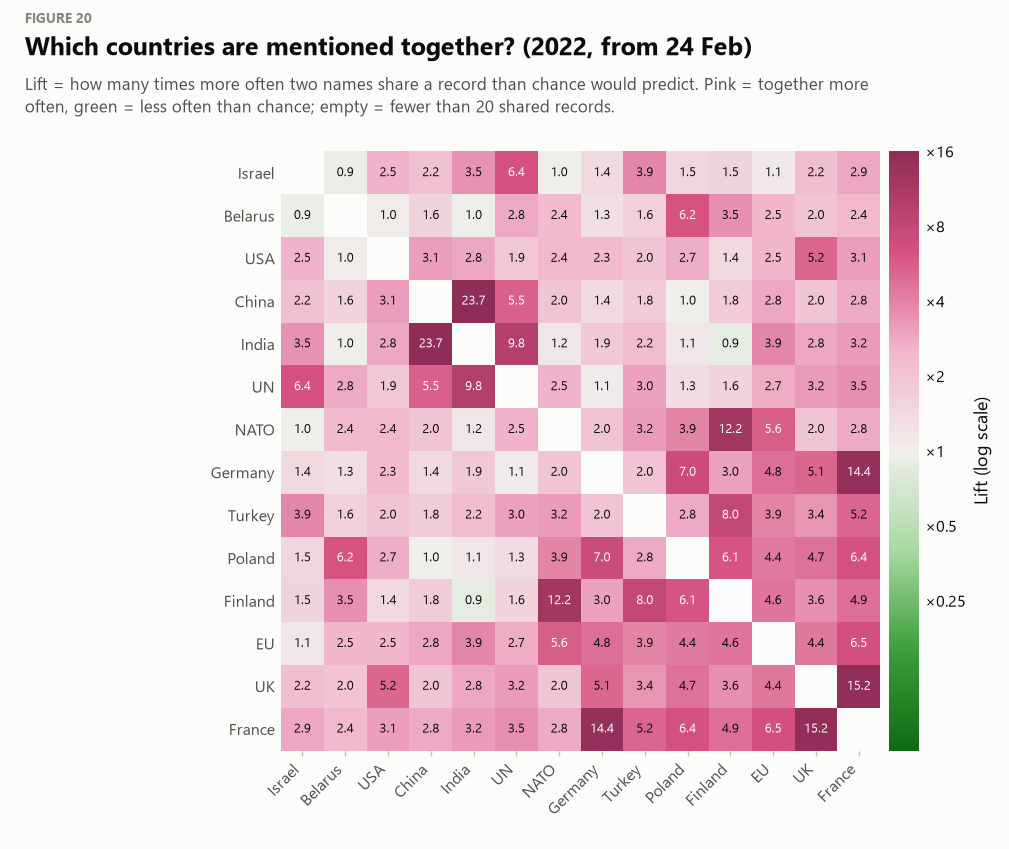

In [23]:
F2 = FOCUS[FOCUS["per"] == 2]
top14 = F2["ent"].value_counts().index[:14].tolist()
sub_ = F2[F2["ent"].isin(top14)]
rows_u, inv = np.unique(sub_["row"].to_numpy(), return_inverse=True)
col = pd.Categorical(sub_["ent"].astype(str), categories=top14).codes
M = np.zeros((len(rows_u), len(top14)), np.float32)
M[inv, col] = 1
co = M.T @ M
Ntot = N_CORE[2]
p_ = np.diag(co) / Ntot
lift = (co / Ntot) / np.outer(p_, p_)
L = np.log2(np.where(co >= 20, lift, np.nan))
np.fill_diagonal(L, np.nan)
Lz = np.nan_to_num(L)
w_, v_ = np.linalg.eigh(Lz)
order = np.argsort(v_[:, -1])
L, lift_o, names = L[order][:, order], lift[order][:, order], [top14[i] for i in order]
lim = min(np.nanmax(np.abs(L)), 4) if np.isfinite(L).any() else 1
fig, ax = frame("Which countries are mentioned together? (2022, from 24 Feb)",
                "Lift = how many times more often two names share a record than chance would predict. "
                "Pink = together more often, green = less often than chance; empty = fewer than 20 shared records.",
                h=6.2, w=8.8)
im = ax.imshow(L, cmap=DIV_PG, norm=TwoSlopeNorm(0, -lim, lim), interpolation="nearest")
for i in range(len(names)):
    for j in range(len(names)):
        if np.isfinite(L[i, j]):
            ax.text(j, i, f"{lift_o[i, j]:.1f}", ha="center", va="center", fontsize=7.2,
                    color="white" if abs(L[i, j]) > lim * 0.6 else INK)
ax.set_xticks(range(len(names)), names, rotation=45, ha="right")
ax.set_yticks(range(len(names)), names)
ax.grid(False)
ax.spines[:].set_visible(False)
cb = heat_colorbar(ax, im, "Lift (log scale)", fraction=0.04)
ticks = [t for t in (-2, -1, 0, 1, 2, 3, 4) if -lim <= t <= lim]
cb.set_ticks(ticks, labels=[f"×{2.0 ** t:g}" for t in ticks])
plt.show()
pairs = [(names[i], names[j], lift_o[i, j]) for i in range(len(names)) for j in range(i + 1, len(names)) if np.isfinite(L[i, j])]
pairs.sort(key=lambda t: -t[2])
say("Strongest pairs: " + "; ".join(f"{a} + {b} (×{l:.1f})" for a, b, l in pairs[:6]) + ".",
    "Weakest pairs: " + "; ".join(f"{a} + {b} (×{l:.2f})" for a, b, l in pairs[-3:]) + ".")

**What we see.** The darkest cells are China–India, France–UK, France–Germany and Finland–NATO. Finland also often appears together with Turkey.

**What it means.** Countries are mentioned together when they play the same role: China and India stayed neutral and kept buying Russian oil; France, Germany and the UK are discussed as the big European powers; Finland goes with NATO and Turkey because of its NATO application.

### 4.3 What kind of support? (Q6)

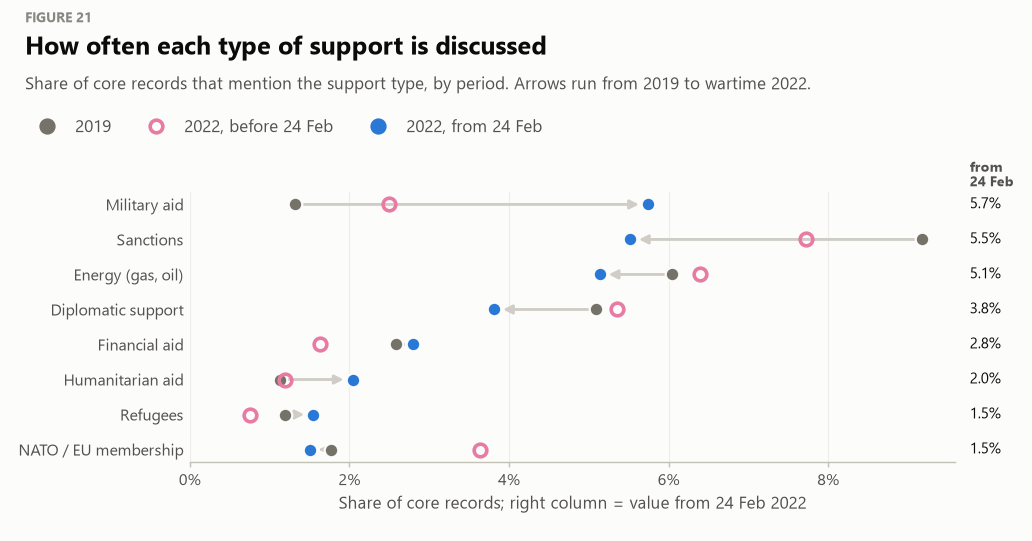

In [24]:
sup = CORE.groupby("period", observed=True)[[f"s_{s}" for s in SUPPORT]].mean() * 100
sup.columns = SUPPORT
order_s = sup.loc["2022_war"].sort_values().index
FIGREF["support_dots"] = FIG["n"] + 1
fig, ax = frame("How often each type of support is discussed",
                "Share of core records that mention the support type, by period. Arrows run from 2019 to wartime 2022.",
                h=3.3, w=9, legend=period_legend())
period_arrows(ax, sup.T.loc[order_s].rename(index=SUP_LABEL), "{:.1f}%")
ax.set_xlim(left=0)
ax.xaxis.set_major_formatter(pct_fmt())
ax.set_xlabel("Share of core records; right column = value from 24 Feb 2022")
plt.show()
FACTS["support"] = sup
say(f"After the invasion the most discussed support types are " +
    ", ".join(f"{SUP_LABEL[s].lower()} ({sup.loc['2022_war', s]:.1f}%)" for s in order_s[::-1][:3]) + ".",
    "Biggest change vs 2019: " + ", ".join(f"{SUP_LABEL[s].lower()} ×{sup.loc['2022_war', s] / sup.loc['2019', s]:.1f}"
                                          for s in (sup.loc['2022_war'] / sup.loc['2019'].replace(0, np.nan)).sort_values(ascending=False).index[:3]) + ".")

**What we see.** Military aid moved far to the right after the invasion and became the most discussed type of support. Sanctions and energy moved to the left compared with 2019 and with the weeks before the invasion.

**What it means.** After 24 February people talked above all about weapons for Ukraine. Sanctions and gas were bigger topics before the war (the Crimea sanctions, the Nord Stream 2 pipeline).

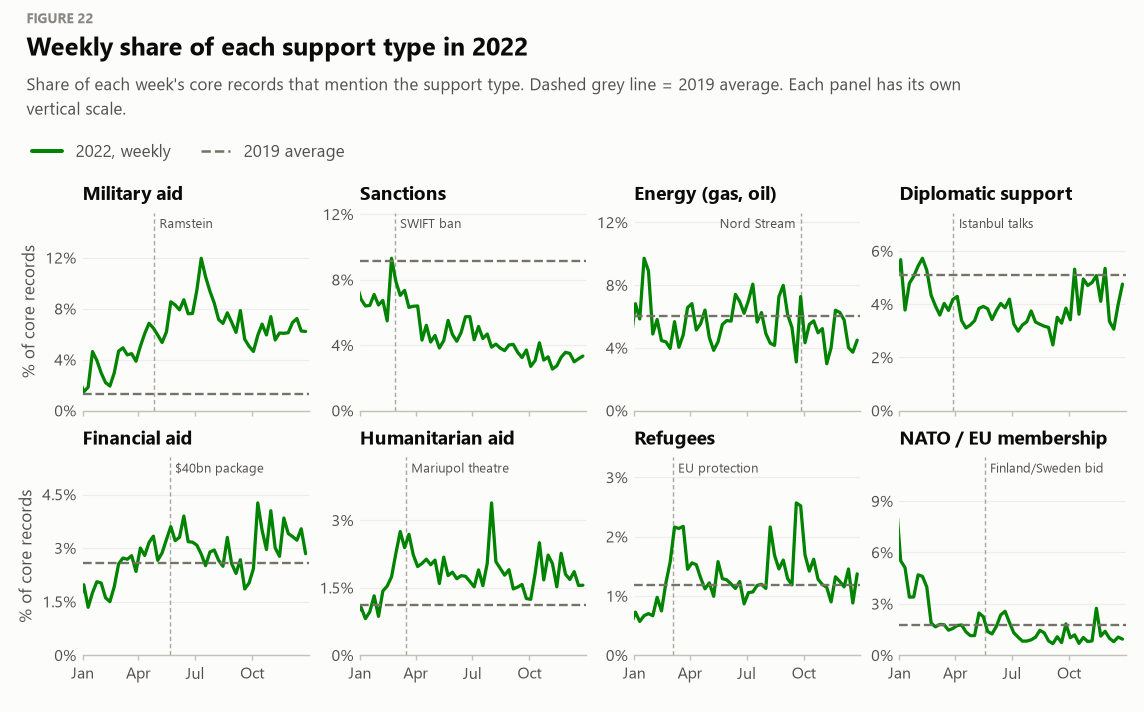

In [25]:
ws = CORE[CORE["year"] == 2022].groupby("week")[[f"s_{s}" for s in SUPPORT]].mean() * 100
ws.columns = SUPPORT
order_p = sup.loc["2022_war"].sort_values(ascending=False).index
fig, axes = frame("Weekly share of each support type in 2022",
                  "Share of each week's core records that mention the support type. Dashed grey line = 2019 average. "
                  "Each panel has its own vertical scale.",
                  nrows=2, ncols=4, h=4.6, sharex=True,
                  legend=([line_h(GREEN), line_h(C19, lw=1.4, ls="--")], ["2022, weekly", "2019 average"]))
weekly_panels(axes, ws, sup.loc["2019"], list(order_p), GREEN, events=SUPPORT_EVENTS, titles=SUP_LABEL)
plt.show()
sp_ = {s: ws[s].idxmax() for s in SUPPORT}
aut = ws.loc["2022-09-01":].mean() / ws.loc["2022-03-01":"2022-05-31"].mean()
FACTS["energy_autumn_vs_spring"] = aut["energy"]
say(*[f"{SUP_LABEL[s]}: peak in the week of {day_month(w)} ({ws.loc[w, s]:.1f}%)." for s, w in sp_.items()],
    f"Energy in September–December vs March–May: ×{aut['energy']:.2f}.")

**What we see.** Military aid grows from March to a peak in summer. Sanctions are highest in the week of the invasion and then slowly fall. NATO/EU membership is high in January and then drops.

**What it means.** The support conversation changed with the war: first sanctions as the quick answer, then a long discussion about weapons. NATO membership was a big topic before the war, when Russia demanded guarantees that NATO would not expand.

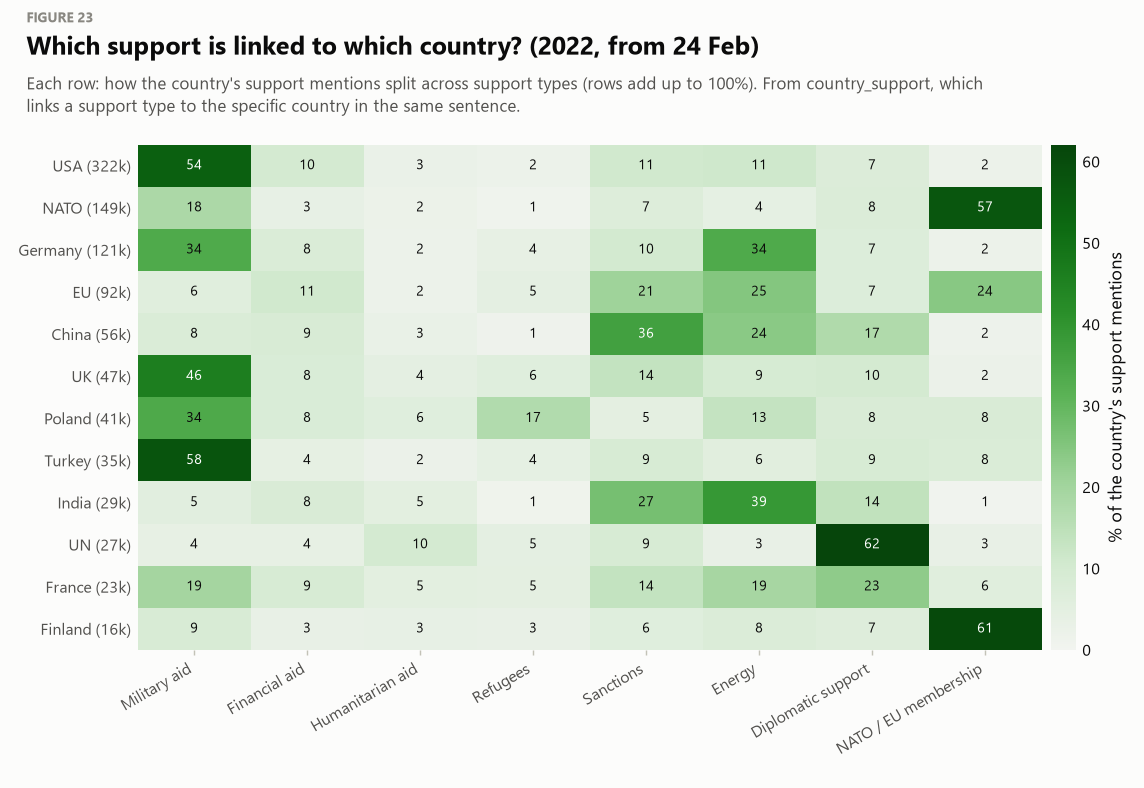

In [26]:
SW = SUPP[SUPP["per"] == 2]
tops = [e for e in SW["ent"].value_counts().index[:13] if e not in ("Ukraine", "Russia")][:12]
ct = SW[SW["ent"].isin(tops)].groupby(["ent", "kind"], observed=True).size().unstack(fill_value=0)
ct = ct.reindex(index=tops, columns=SUPPORT, fill_value=0)
shr = ct.div(ct.sum(axis=1), axis=0) * 100
FIGREF["support_heat"] = FIG["n"] + 1
fig, ax = frame("Which support is linked to which country? (2022, from 24 Feb)",
                "Each row: how the country's support mentions split across support types (rows add up to 100%). "
                "From country_support, which links a support type to the specific country in the same sentence.",
                h=0.38 * len(tops) + 1.1, w=10)
im = ax.imshow(shr.to_numpy(), cmap=SEQ_GREEN, vmin=0, vmax=max(60, shr.to_numpy().max()), aspect="auto")
for i in range(len(tops)):
    for j in range(len(SUPPORT)):
        v = shr.iloc[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                color="white" if v > 0.55 * max(60, shr.to_numpy().max()) else INK)
ax.set_xticks(range(len(SUPPORT)), [SUP_LABEL[s].replace(" (gas, oil)", "") for s in SUPPORT], rotation=30, ha="right")
ax.set_yticks(range(len(tops)), [f"{e} ({human(ct.loc[e].sum())})" for e in tops])
ax.grid(False)
ax.spines[:].set_visible(False)
cb = heat_colorbar(ax, im, "% of the country's support mentions", fraction=0.03)
plt.show()
dom = shr.idxmax(axis=1)
lift_s = shr / (ct.sum() / ct.sum().sum() * 100)
say(*[f"{e}: mostly {SUP_LABEL[dom[e]].lower()} ({shr.loc[e, dom[e]]:.0f}%); most over-represented vs other countries: "
      f"{SUP_LABEL[lift_s.loc[e].idxmax()].lower()} (×{lift_s.loc[e].max():.1f})." for e in tops[:8]])

**What we see.** Each row has one or two dark cells. The USA, the UK, Turkey and Poland are dark in military aid; Germany in military aid and energy; China and India in sanctions and energy; NATO and Finland in membership; the UN in diplomacy. Poland also stands out in refugees.

**What it means.** Each country has a clear role in the discussion: who sends weapons, who depends on Russian gas or oil, who joins NATO and who takes in refugees.

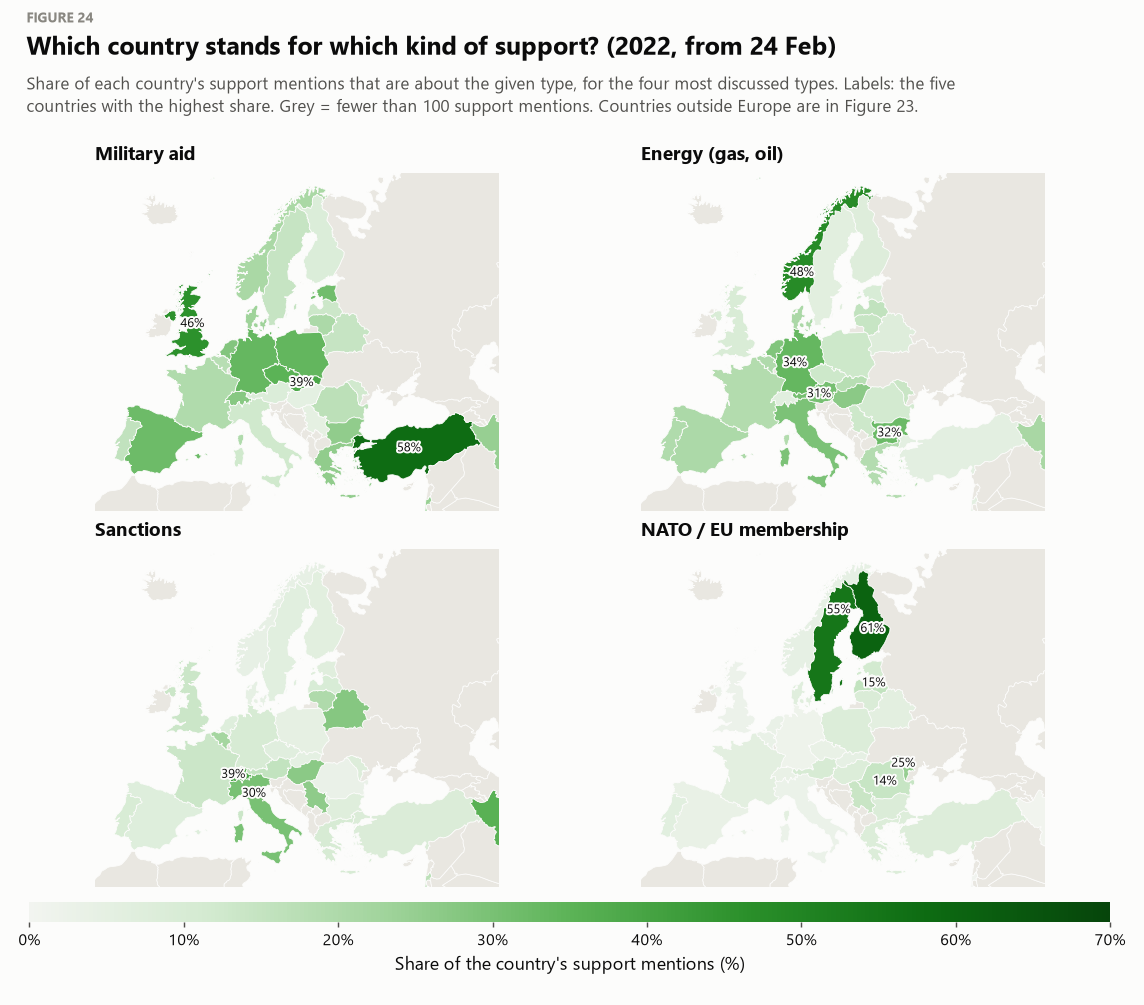

In [27]:
if GEO is not None:
    kinds4 = SW["kind"].value_counts().index[:4].tolist()          # the four most discussed support types
    ctm = SW.groupby(["ent", "kind"], observed=True).size().unstack(fill_value=0).reindex(columns=SUPPORT, fill_value=0)
    ctm = ctm[(ctm.sum(axis=1) >= 100) & ctm.index.isin(list(ENT_A3))]
    shm = ctm.div(ctm.sum(axis=1), axis=0) * 100
    vmax = float(min(80, max(20, np.ceil(shm[kinds4].to_numpy().max() / 10) * 10)))
    norm = Normalize(0, vmax)
    FIGREF["support_map"] = FIG["n"] + 1
    fig, axes = frame("Which country stands for which kind of support? (2022, from 24 Feb)",
                      "Share of each country's support mentions that are about the given type, for the four most discussed "
                      "types. Labels: the five countries with the highest share. Grey = fewer than 100 support mentions. "
                      f"Countries outside Europe are in Figure {FIGREF['support_heat']}.",
                      nrows=2, ncols=2, h=7.6, w=10)
    for ax, k in zip(axes.ravel(), kinds4):
        v = shm[k]
        top5 = v.sort_values(ascending=False).head(5)
        draw_map(ax, "europe", to_a3(v), SEQ_GREEN, norm, laea, labels={ENT_A3[e]: f"{x:.0f}%" for e, x in top5.items()})
        europe_axes(ax)
        ax.set_title(SUP_LABEL[k])
    map_colorbar(axes, SEQ_GREEN, norm, "Share of the country's support mentions (%)", fmt=lambda t: f"{t:g}%",
                 ticks=list(range(0, int(vmax) + 1, 10)))
    plt.show()
    say(*[f"{SUP_LABEL[k]}: " + ", ".join(f"{e} ({x:.0f}%)" for e, x in shm[k].sort_values(ascending=False).head(4).items()) + "."
          for k in kinds4])

**What we see.** Turkey and the UK are the darkest on the military-aid map, Norway and Germany on the energy map, Switzerland and Italy on the sanctions map, Finland and Sweden on the membership map.

**What it means.** The maps show the same roles across Europe. Switzerland stands out on sanctions because it joined the EU sanctions despite its neutrality.

### 4.4 Themes and weapons in the text

Keyword searches over the full text of every record (word boundaries, case-insensitive). They are blunt — "nuclear" also catches nuclear power plants — but they show *when* each theme took over the conversation.

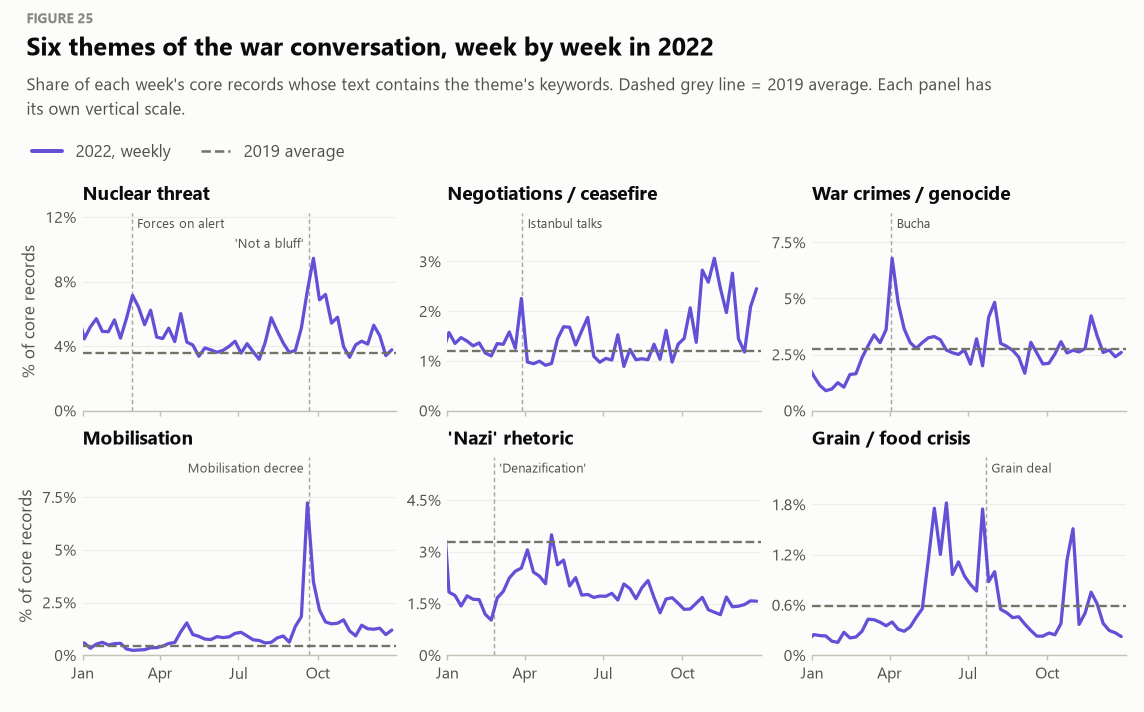

In [28]:
wt = CORE[CORE["year"] == 2022].groupby("week")[[f"kw_{k}" for k in THEMES]].mean() * 100
th19 = CORE[CORE["year"] == 2019][[f"kw_{k}" for k in THEMES]].mean() * 100
wt.columns, th19.index = list(THEMES), list(THEMES)
fig, axes = frame("Six themes of the war conversation, week by week in 2022",
                  "Share of each week's core records whose text contains the theme's keywords. Dashed grey line = 2019 average. "
                  "Each panel has its own vertical scale.",
                  nrows=2, ncols=3, h=4.6, sharex=True,
                  legend=([line_h(VIOLET), line_h(C19, lw=1.4, ls="--")], ["2022, weekly", "2019 average"]))
weekly_panels(axes, wt, th19, list(THEMES), VIOLET, events=THEME_EVENTS, titles=THEMES)
plt.show()
say(*[f"{name}: peak in the week of {day_month(wt[k].idxmax())} ({wt[k].max():.1f}% of records; "
      f"2019 average {th19[k]:.1f}%)." for k, name in THEMES.items()])

**What we see.** Each theme has its own peak: war crimes in early April, the nuclear threat and mobilisation in late September, grain in June–July, negotiations in November. "Nazi" rhetoric stays below the 2019 level most of the year.

**What it means.** The topics follow real events: Bucha, Putin's mobilisation and nuclear threats, the grain blockade and deal, the talk about negotiations after Kherson. Russia's "denazification" story did not catch on in these communities.

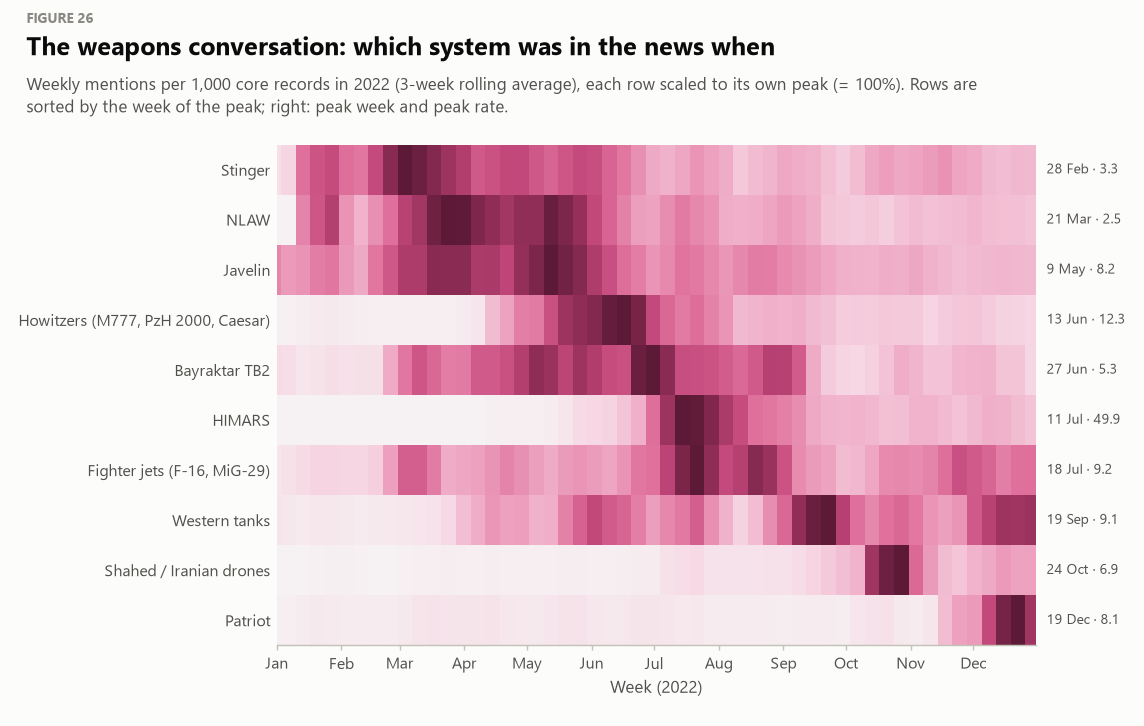

In [29]:
ww = CORE[CORE["year"] == 2022].groupby("week")[[f"kw_{k}" for k in WEAPONS]].mean() * 1000
ww.columns = list(WEAPONS)
ww = ww.loc[:, ww.sum() > 0].rolling(3, center=True, min_periods=1).mean()
peak_w = ww.idxmax().sort_values()
wn = (ww / ww.max())[peak_w.index]
fig, ax = frame("The weapons conversation: which system was in the news when",
                "Weekly mentions per 1,000 core records in 2022 (3-week rolling average), each row scaled to its own peak (= 100%). "
                "Rows are sorted by the week of the peak; right: peak week and peak rate.",
                h=0.42 * len(wn.columns) + 0.9, w=10)
x0, x1 = mdates.date2num(wn.index.min()), mdates.date2num(wn.index.max() + pd.Timedelta(days=7))
im = ax.imshow(wn.T.to_numpy() * 100, aspect="auto", cmap=SEQ_PINK, vmin=0, vmax=100, interpolation="nearest",
               extent=[x0, x1, len(wn.columns) - 0.5, -0.5])
ax.xaxis_date()
month_axis(ax)
ax.set_yticks(range(len(wn.columns)), [WEAPONS[k] for k in wn.columns])
for i, k in enumerate(wn.columns):
    ax.annotate(f"{day_month(peak_w[k])} · {ww[k].max():.1f}", xy=(1, i), xycoords=("axes fraction", "data"),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=INK2)
ax.grid(False)
ax.set_xlabel("Week (2022)")
plt.show()
say("Order of peaks: " + " → ".join(f"{WEAPONS[k]} ({day_month(w)})" for k, w in peak_w.items()) + ".",
    "For comparison, the war's timeline: Javelin, NLAW and Stinger were the symbols of the first weeks; M777 howitzers "
    "arrived in April–May; HIMARS from late June; Shahed drones hit Ukrainian cities from September; the US promised "
    "Patriots in December 2022; Western tanks and F-16s were only debated in 2022.")

**What we see.** The dark cells move from the top left to the bottom right: Stinger and NLAW in spring, howitzers and Bayraktar in June, HIMARS in July, Western tanks in September, Shahed drones in October, Patriot in December.

**What it means.** The weapons discussion repeats the history of the war: first portable weapons for defence, then artillery and HIMARS for the counteroffensives, then air defence against Russian drone and missile attacks.

### 4.5 Words that set the periods apart

Instead of a word cloud we use the **weighted log-odds ratio with an informative Dirichlet prior** (Monroe, Colaresi & Quinn, 2008). For every word or two-word phrase it measures how much more typical it is of one period than of the other, while shrinking rare words towards zero; the value is a z-score. Computed on a random sample of up to 60,000 core records per period, counting each word once per record.

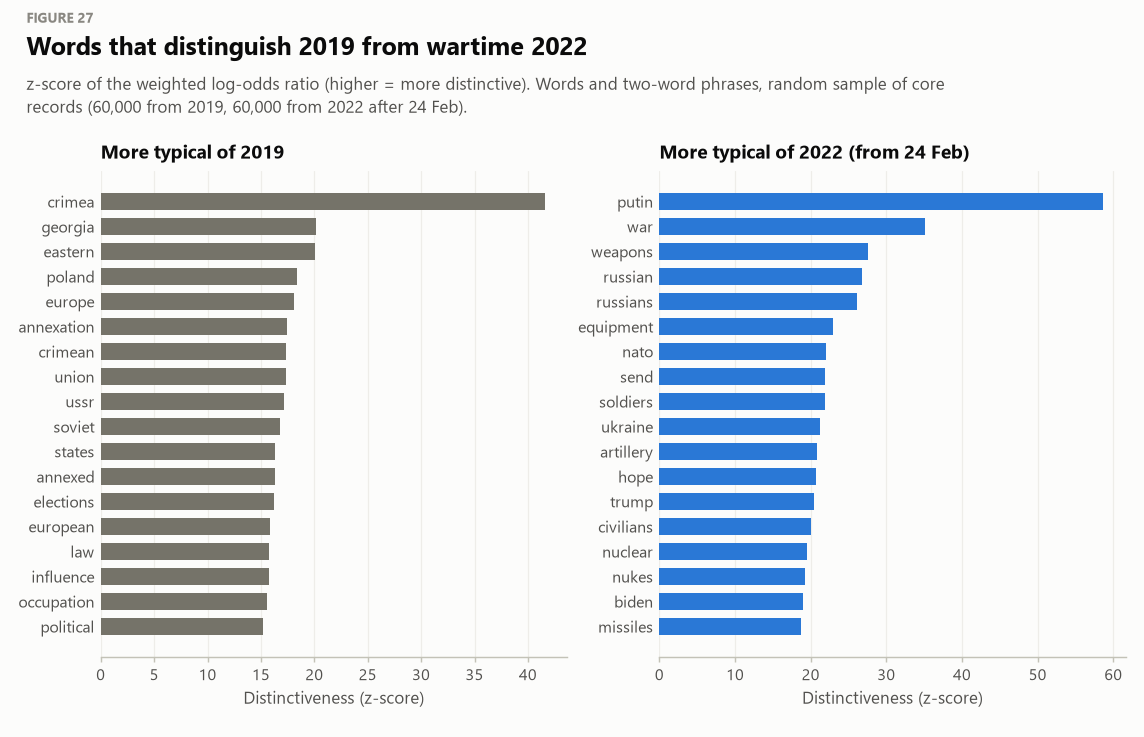

In [30]:
cA = term_counts(SAMPLE.loc[SAMPLE["per"] == 0, "text"])
cB = term_counts(SAMPLE.loc[SAMPLE["per"] == 2, "text"])
z = log_odds(cB, cA)          # positive = more typical of wartime 2022
k = 18
war_terms, terms19 = z.nlargest(k)[::-1], z.nsmallest(k)[::-1].abs()
fig, axes = frame("Words that distinguish 2019 from wartime 2022",
                  "z-score of the weighted log-odds ratio (higher = more distinctive). Words and two-word phrases, "
                  f"random sample of core records ({(SAMPLE['per'] == 0).sum():,} from 2019, {(SAMPLE['per'] == 2).sum():,} from 2022 after 24 Feb).",
                  ncols=2, h=5.2)
for ax, s, c, name in ((axes[0], terms19.sort_values(), C19, "More typical of 2019"),
                       (axes[1], war_terms, BLUE, "More typical of 2022 (from 24 Feb)")):
    ax.barh(range(len(s)), s.to_numpy(), color=c, height=0.66)
    ax.set_yticks(range(len(s)), s.index)
    ax.set_title(name)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Distinctiveness (z-score)")
plt.show()
FACTS["words19"], FACTS["words22"] = terms19.sort_values(ascending=False).index[:8].tolist(), war_terms[::-1].index[:8].tolist()
say(f"Most typical of 2019: {', '.join(FACTS['words19'])}.",
    f"Most typical of wartime 2022: {', '.join(FACTS['words22'])}.")

**What we see.** Typical 2019 words are Crimea, Georgia, annexation, Soviet, elections. Typical 2022 words are Putin, war, weapons, soldiers, artillery, civilians, nukes.

**What it means.** In 2019 people talked about a frozen conflict and history; in 2022 — about a real war happening right now.

## 5. Tone: how people talk about Ukraine, Russia and other countries (Q7)

Every (record, country) pair was labelled by our fine-tuned model as **negative (−1), neutral (0) or positive (+1)** towards that country. We summarise tone with the **net tone** = share of positive − share of negative pairs, in percentage points (pp): +20 means positive statements outnumber negative ones by 20 points. Estimates weight each record by 1/√thread_n; bands are 95% confidence intervals.

### 5.1 Can we trust the labels?

Before reading tone trends we check the model on 389 hand-labelled pairs that were never used for training.

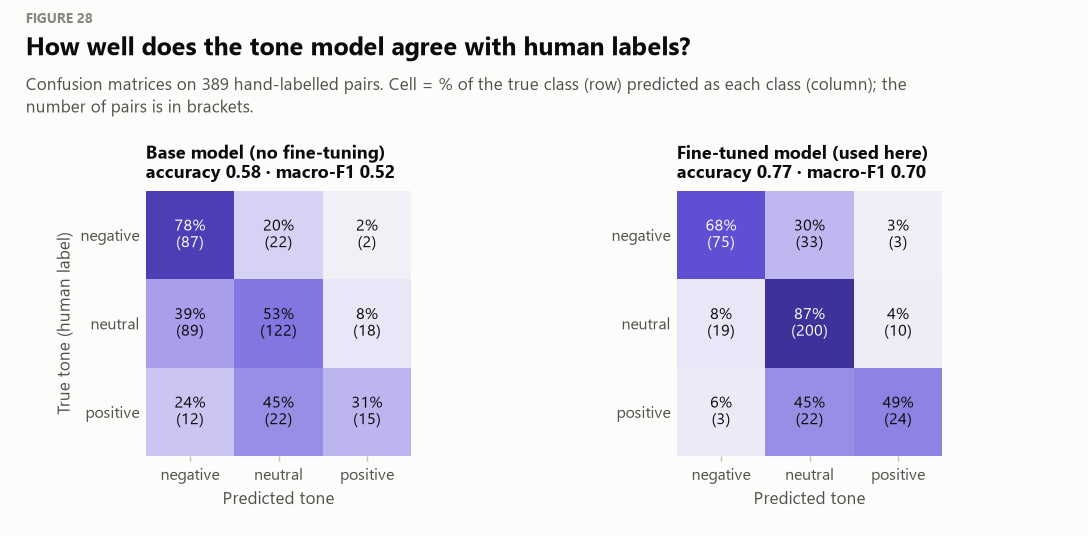

In [31]:
LAB = ["negative", "neutral", "positive"]
gold_path = REACTIONS_DIR / "gold_predictions_ft2.csv"
if gold_path.exists():
    gold = pd.read_csv(gold_path)
    cms = {name: pd.crosstab(pd.Categorical(gold["y"], LAB), pd.Categorical(gold[col], LAB), dropna=False).to_numpy()
           for name, col in (("Base model (no fine-tuning)", "pred_base"), ("Fine-tuned model (used here)", "pred_ft2"))}
else:   # numbers from the evaluation run in reaction_finetune_colab.ipynb
    cms = {"Base model (no fine-tuning)": np.array([[87, 22, 2], [89, 122, 18], [12, 22, 15]]),
           "Fine-tuned model (used here)": np.array([[75, 33, 3], [19, 200, 10], [3, 22, 24]])}


fig, axes = frame("How well does the tone model agree with human labels?",
                  "Confusion matrices on 389 hand-labelled pairs. Cell = % of the true class (row) predicted as each class "
                  "(column); the number of pairs is in brackets.",
                  ncols=2, h=3.4, w=9.5)
for ax, (name, cm) in zip(axes, cms.items()):
    acc, f1, rec = scores(cm)
    rn = cm / cm.sum(axis=1, keepdims=True) * 100
    ax.imshow(rn, cmap=SEQ_VIOLET, vmin=0, vmax=100)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{rn[i, j]:.0f}%\n({cm[i, j]})", ha="center", va="center", fontsize=8.6,
                    color="white" if rn[i, j] > 55 else INK)
    ax.set_xticks(range(3), LAB)
    ax.set_yticks(range(3), LAB)
    ax.set_xlabel("Predicted tone")
    ax.set_title(f"{name}\naccuracy {acc:.2f} · macro-F1 {f1:.2f}", fontsize=9.8)
    ax.grid(False)
    ax.spines[:].set_visible(False)
axes[0].set_ylabel("True tone (human label)")
plt.show()
cm = cms["Fine-tuned model (used here)"]
acc, f1, rec = scores(cm)
true_net = (cm[2].sum() - cm[0].sum()) / cm.sum()
pred_net = (cm[:, 2].sum() - cm[:, 0].sum()) / cm.sum()
FACTS.update(model_acc=acc, model_f1=f1, model_rec=rec, gold_true_net=true_net, gold_pred_net=pred_net)
say(f"Fine-tuning raised accuracy from {scores(cms['Base model (no fine-tuning)'])[0]:.2f} to **{acc:.2f}** and "
    f"macro-F1 from {scores(cms['Base model (no fine-tuning)'])[1]:.2f} to **{f1:.2f}**.",
    f"Recall by class: negative {rec[0]:.0%}, neutral {rec[1]:.0%}, positive {rec[2]:.0%}. The model misses about half of "
    f"the positive statements, so absolute positive shares below are **underestimates**.",
    f"What matters for trends is the aggregate: on the labelled pairs the true net tone is {true_net * 100:+.1f} pp and "
    f"the model's is {pred_net * 100:+.1f} pp — errors in both directions mostly cancel out.")

**What we see.** The right matrix (our fine-tuned model) has a much darker diagonal than the left one, so it agrees with people much more often. Its weak spot is positive statements: many of them are labelled as neutral.

**What it means.** The model is good enough to show how tone changes. It finds a bit fewer positive statements than there really are, so we compare tone between periods and countries rather than trusting exact levels.

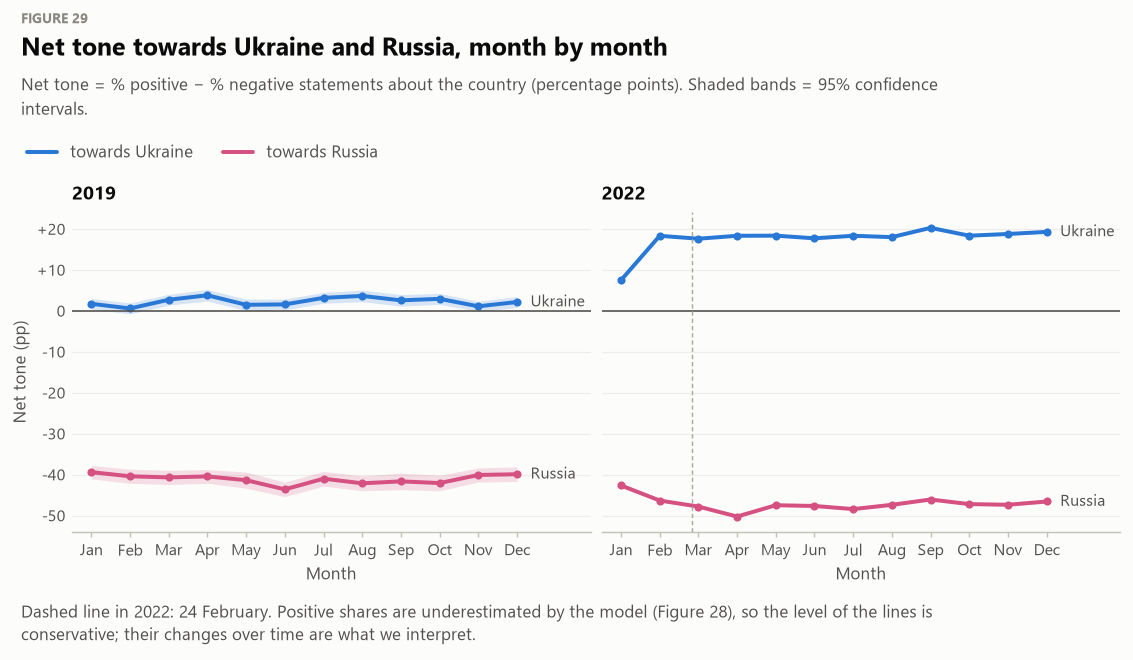

In [32]:
UR = RC[RC["ent"].isin(["Ukraine", "Russia"])]
mt = net_table(UR.assign(ent=UR["ent"].astype(str)), ["ent", "year", "mon"])
TONE_COLOR = {"Ukraine": BLUE, "Russia": RUSSIA_COLOR}
FIGREF["tone_month"] = FIG["n"] + 1
fig, axes = frame("Net tone towards Ukraine and Russia, month by month",
                  "Net tone = % positive − % negative statements about the country (percentage points). "
                  "Shaded bands = 95% confidence intervals.",
                  ncols=2, h=3.7, sharey=True,
                  legend=([line_h(BLUE), line_h(RUSSIA_COLOR)], ["towards Ukraine", "towards Russia"]),
                  note=f"Dashed line in 2022: 24 February. Positive shares are underestimated by the model (Figure {FIG['n']}), "
                       "so the level of the lines is conservative; their changes over time are what we interpret.")
for ax, y in zip(axes, (2019, 2022)):
    for e in ("Ukraine", "Russia"):
        try:
            t = mt.loc[(e, y)].reindex(range(1, 13))
        except KeyError:
            continue
        ax.fill_between(t.index, (t["net"] - 1.96 * t["se"]) * 100, (t["net"] + 1.96 * t["se"]) * 100,
                        color=TONE_COLOR[e], alpha=0.18, lw=0)
        ax.plot(t.index, t["net"] * 100, color=TONE_COLOR[e], lw=2.2, marker="o", ms=3.5)
        ax.text(12.35, t["net"].iloc[-1] * 100, e, va="center", fontsize=8.6, color=INK2)
    ax.axhline(0, color=INK2, lw=0.9)
    month_index_axis(ax)
    ax.set_xlim(0.5, 13.9)
    ax.set_title(str(y))
    ax.set_xlabel("Month")
axes[1].axvline(2 + 23 / 28, color="#a9a79e", lw=0.8, ls=(0, (3, 2)))
axes[0].set_ylabel("Net tone (pp)")
axes[0].yaxis.set_major_formatter(SIGNED)
plt.show()
pt = net_table(UR.assign(ent=UR["ent"].astype(str)), ["ent", "period"])
FACTS["net_ua"], FACTS["net_ru"] = pt.loc["Ukraine", "net"], pt.loc["Russia", "net"]
say(*[f"Towards {e}: " + " → ".join(f"{PERIOD_LABEL[p]} {pt.loc[(e, p), 'net'] * 100:+.0f} pp" for p in PERIODS
                                     if (e, p) in pt.index) + "." for e in ("Ukraine", "Russia")],
    f"Ukraine after the invasion vs 2019: net {(pt.loc[('Ukraine', '2022_war'), 'net'] - pt.loc[('Ukraine', '2019'), 'net']) * 100:+.0f} pp; "
    f"positive share {pt.loc[('Ukraine', '2019'), 'pos_share']:.0%} → {pt.loc[('Ukraine', '2022_war'), 'pos_share']:.0%}, "
    f"negative share {pt.loc[('Ukraine', '2019'), 'neg_share']:.0%} → {pt.loc[('Ukraine', '2022_war'), 'neg_share']:.0%}.",
    f"Russia was already viewed negatively in 2019 ({pt.loc[('Russia', '2019'), 'net'] * 100:+.0f} pp); the war made it "
    f"{abs(pt.loc[('Russia', '2022_war'), 'net'] - pt.loc[('Russia', '2019'), 'net']) * 100:.0f} pp "
    f"{'more' if pt.loc[('Russia', '2022_war'), 'net'] < pt.loc[('Russia', '2019'), 'net'] else 'less'} negative.")

**What we see.** The Ukraine line is just above zero in 2019, jumps up in February 2022 and stays high for the rest of the year. The Russia line is far below zero in both years and goes a bit lower in 2022.

**What it means.** Reddit became much more supportive of Ukraine after the invasion, and the already negative view of Russia became even more negative.

### 5.2 Tone towards every country

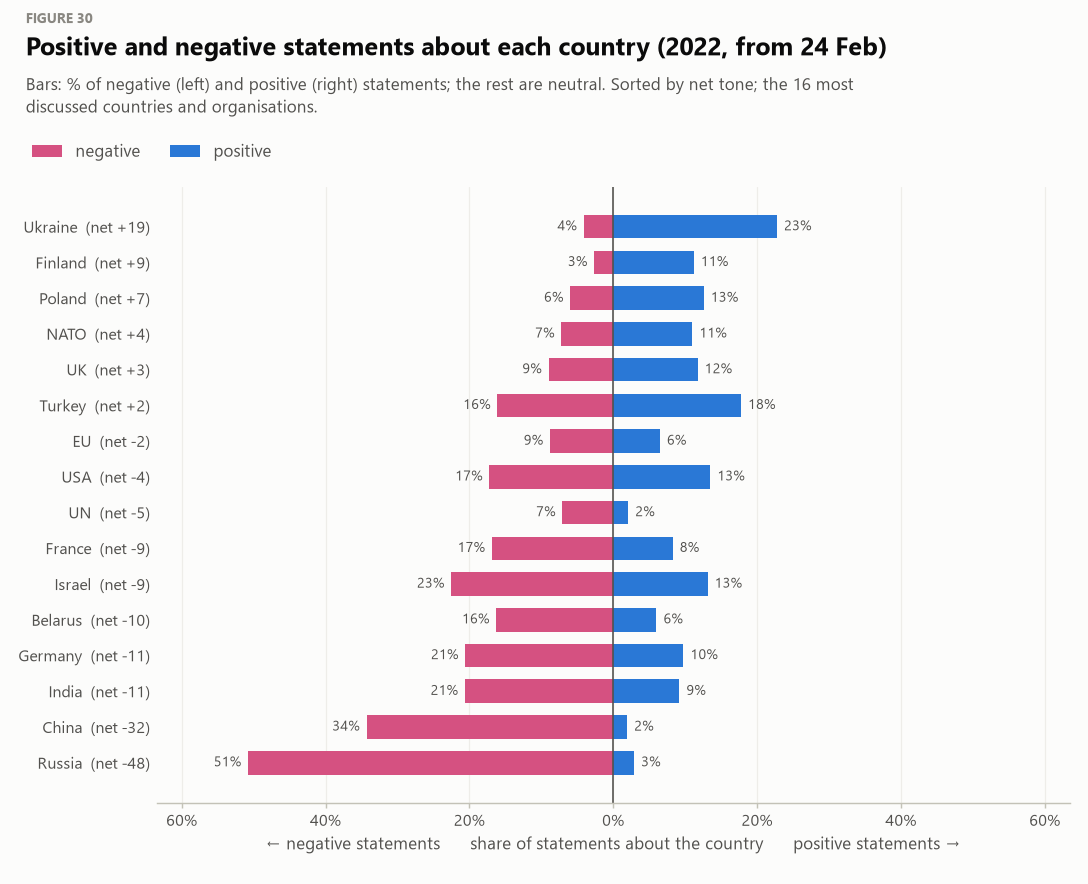

In [33]:
TW = RC[RC["per"] == 2]
TT = net_table(TW, ["ent"])
top16 = TT[TT["n"] >= 300].nlargest(16, "n").sort_values("net")
fig, ax = frame("Positive and negative statements about each country (2022, from 24 Feb)",
                "Bars: % of negative (left) and positive (right) statements; the rest are neutral. "
                "Sorted by net tone; the 16 most discussed countries and organisations.",
                h=0.34 * len(top16) + 0.7, w=9.5,
                legend=([patch_h(NEG), patch_h(POS)], ["negative", "positive"]))
y = np.arange(len(top16))
ax.barh(y, -top16["neg_share"] * 100, color=NEG, height=0.66)
ax.barh(y, top16["pos_share"] * 100, color=POS, height=0.66)
for yi, (e, r) in zip(y, top16.iterrows()):
    ax.text(-r["neg_share"] * 100 - 1, yi, f"{r['neg_share'] * 100:.0f}%", ha="right", va="center", fontsize=7.8, color=INK2)
    ax.text(r["pos_share"] * 100 + 1, yi, f"{r['pos_share'] * 100:.0f}%", ha="left", va="center", fontsize=7.8, color=INK2)
ax.set_yticks(y, [f"{e}  (net {r['net'] * 100:+.0f})" for e, r in top16.iterrows()])
ax.axvline(0, color=INK2, lw=0.9)
lim = max(top16["neg_share"].max(), top16["pos_share"].max()) * 100 * 1.25
ax.set_xlim(-lim, lim)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{abs(v):.0f}%"))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("← negative statements      share of statements about the country      positive statements →")
plt.show()
say(f"Warmest: " + ", ".join(f"{e} ({r['net'] * 100:+.0f})" for e, r in top16[::-1].head(4).iterrows()) + ".",
    f"Coldest: " + ", ".join(f"{e} ({r['net'] * 100:+.0f})" for e, r in top16.head(4).iterrows()) + ".",
    (f"Most statements are neutral for every country except {', '.join(TT.loc[top16.index][TT.loc[top16.index, 'neu_share'] < 0.5].index)}, "
     f"where negative or positive statements are the majority." if (top16["neu_share"] < 0.5).any() else
     "For every country most statements are neutral; tone differences come from the minority of evaluative statements."))

**What we see.** Ukraine, Finland and Poland have long blue bars and short pink ones. Russia has by far the longest pink bar, then China. Germany, India, Belarus, Israel and France also have more pink than blue.

**What it means.** Countries that help Ukraine are talked about warmly; Russia and countries seen as close to it are criticised. Germany is criticised probably because of its slow decisions on weapons and its dependence on Russian gas.

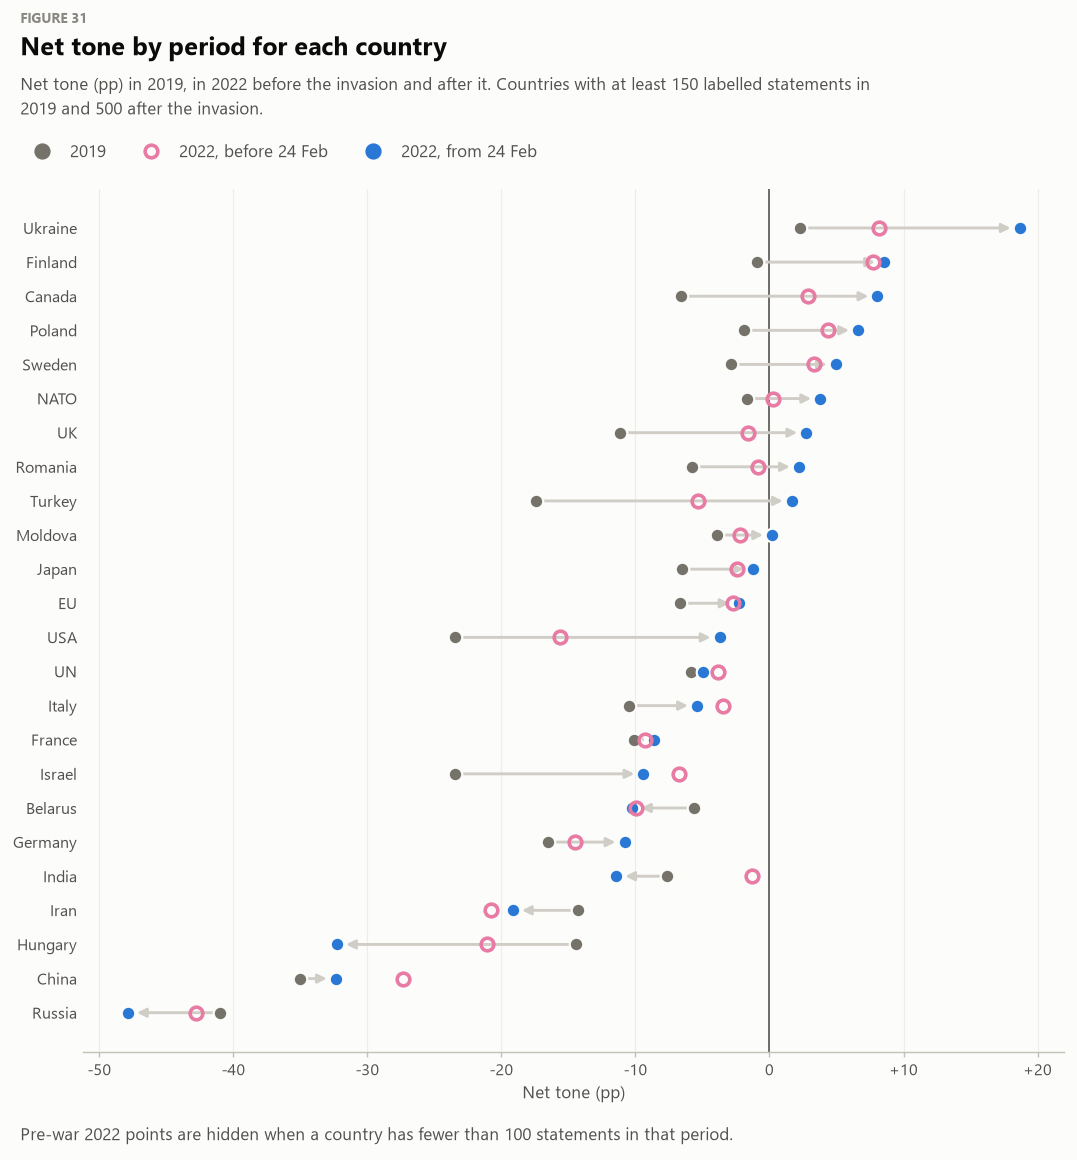

In [34]:
PT = net_table(RC, ["ent", "period"])
nn = PT["n"].unstack()
ok = nn[(nn.get("2019", 0) >= 150) & (nn.get("2022_war", 0) >= 500)].index
net = PT["net"].unstack().loc[ok] * 100
net = net[net.index.isin(TT.nlargest(24, "n").index)].sort_values("2022_war")
fig, ax = frame("Net tone by period for each country",
                "Net tone (pp) in 2019, in 2022 before the invasion and after it. Countries with at least 150 labelled "
                "statements in 2019 and 500 after the invasion.",
                h=0.32 * len(net) + 0.7, w=9.5,
                legend=period_legend(),
                note="Pre-war 2022 points are hidden when a country has fewer than 100 statements in that period.")
for i, (e, r) in enumerate(net.iterrows()):
    ax.annotate("", xy=(r["2022_war"], i), xytext=(r["2019"], i),
                arrowprops=dict(arrowstyle="-|>", color=CONTEXT, lw=1.6, shrinkA=4, shrinkB=5, mutation_scale=10))
    for p in PERIODS:
        if p == "2022_pre" and nn.loc[e].get("2022_pre", 0) < 100:
            continue
        period_dot(ax, r[p], i, p)
ax.set_yticks(range(len(net)), net.index)
ax.axvline(0, color=INK2, lw=0.9)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(SIGNED)
ax.set_xlabel("Net tone (pp)")
plt.show()
dn = (net["2022_war"] - net["2019"]).sort_values()
FACTS["tone_change"] = dn
say("Biggest improvements 2019 → war: " + ", ".join(f"{e} {v:+.0f} pp" for e, v in dn[::-1].head(5).items()) + ".",
    "Biggest declines: " + ", ".join(f"{e} {v:+.0f} pp" for e, v in dn.head(4).items()) + ".")

**What we see.** For most countries the arrow points to the right: they became warmer after the invasion — especially the USA, Turkey, Canada and the UK. Hungary's arrow points strongly to the left; Russia, Iran and Belarus also move left.

**What it means.** Helping Ukraine improved how a country is talked about. Hungary, whose government kept close ties with Russia, became one of the most criticised countries.

### 5.3 The map of sentiment

The same net tone on a map of Europe, 2019 next to wartime 2022, on one colour scale: pink = talked about negatively, blue = positively.

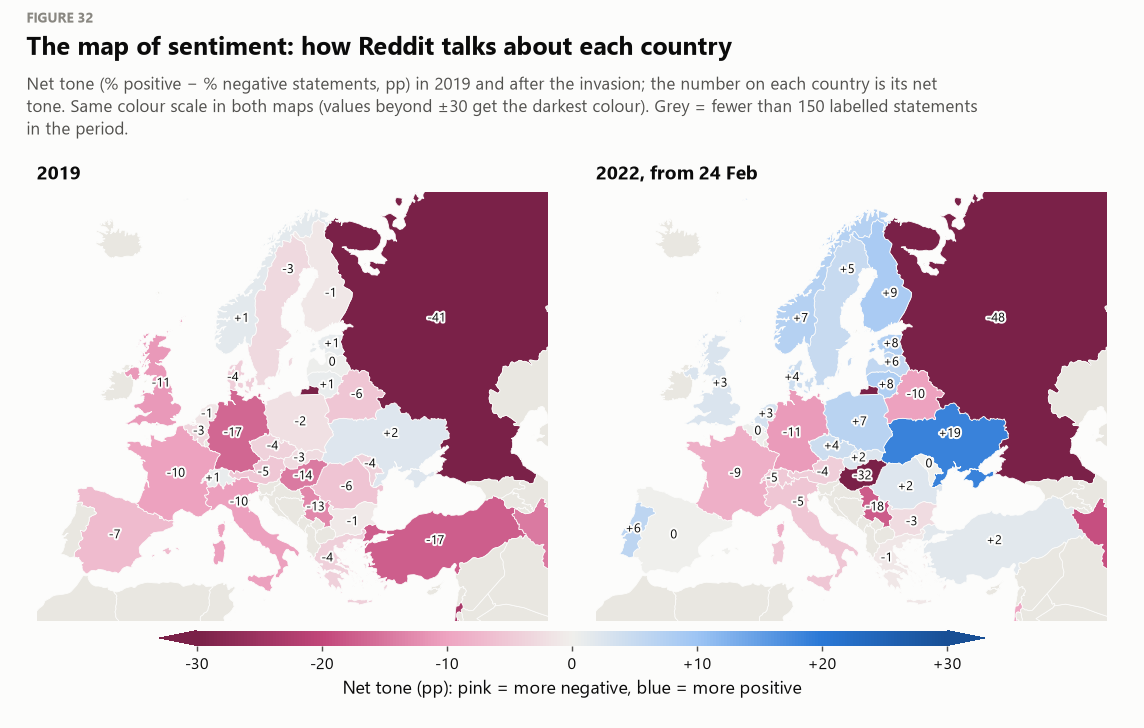

In [35]:
if GEO is None:
    print("Map skipped: eda_assets/countries.json not found next to the notebook.")
else:
    netp, nper = PT["net"].unstack() * 100, PT["n"].unstack()
    lim = 30
    norm = Normalize(-lim, lim)
    FIGREF["tone_map"] = FIG["n"] + 1
    fig, axes = frame("The map of sentiment: how Reddit talks about each country",
                      "Net tone (% positive − % negative statements, pp) in 2019 and after the invasion; the number on each "
                      "country is its net tone. Same colour scale in both maps (values beyond ±30 get the darkest colour). "
                      "Grey = fewer than 150 labelled statements in the period.",
                      ncols=2, h=4.9, w=10)
    shown = {}
    for ax, p, name in zip(axes, ["2019", "2022_war"], ["2019", "2022, from 24 Feb"]):
        t = netp[p][nper[p] >= 150].dropna()
        vals = to_a3(t)
        shown[p] = t
        draw_map(ax, "europe", vals, DIV, norm, laea, labels={a: signed(v) for a, v in vals.items()})
        europe_axes(ax)
        ax.set_title(name)
    map_colorbar(axes, DIV, norm, "Net tone (pp): pink = more negative, blue = more positive", extend="both",
                 ticks=[-30, -20, -10, 0, 10, 20, 30], fmt=lambda t: signed(t))
    plt.show()
    eu = in_europe_view()
    on_map = {e for e, a in ENT_A3.items() if a in eu}
    both = pd.concat(shown, axis=1).dropna()
    both = both[both.index.isin(list(on_map))]
    d_ = (both["2022_war"] - both["2019"]).sort_values()
    eu_war = shown["2022_war"][shown["2022_war"].index.isin(list(on_map))].sort_values()
    say("Warmest on the 2022 map: " + ", ".join(f"{e} ({signed(v)})" for e, v in eu_war[::-1].head(5).items()) + ".",
        "Coldest: " + ", ".join(f"{e} ({signed(v)})" for e, v in eu_war.head(5).items()) + ".",
        "Turned warmer the most: " + ", ".join(f"{e} ({signed(v)} pp)" for e, v in d_[::-1].head(4).items())
        + "; turned colder: " + ", ".join(f"{e} ({signed(v)} pp)" for e, v in d_.head(3).items()) + ".")

**What we see.** In 2019 most of Europe is light pink. In 2022 the north-east turns blue: Finland, Sweden, Norway, the Baltic states and Poland. Germany and France stay pink, while Hungary and Serbia become dark pink.

**What it means.** The countries closest to Russia that strongly supported Ukraine got the warmest words; the countries seen as friendly to Russia got the coldest.

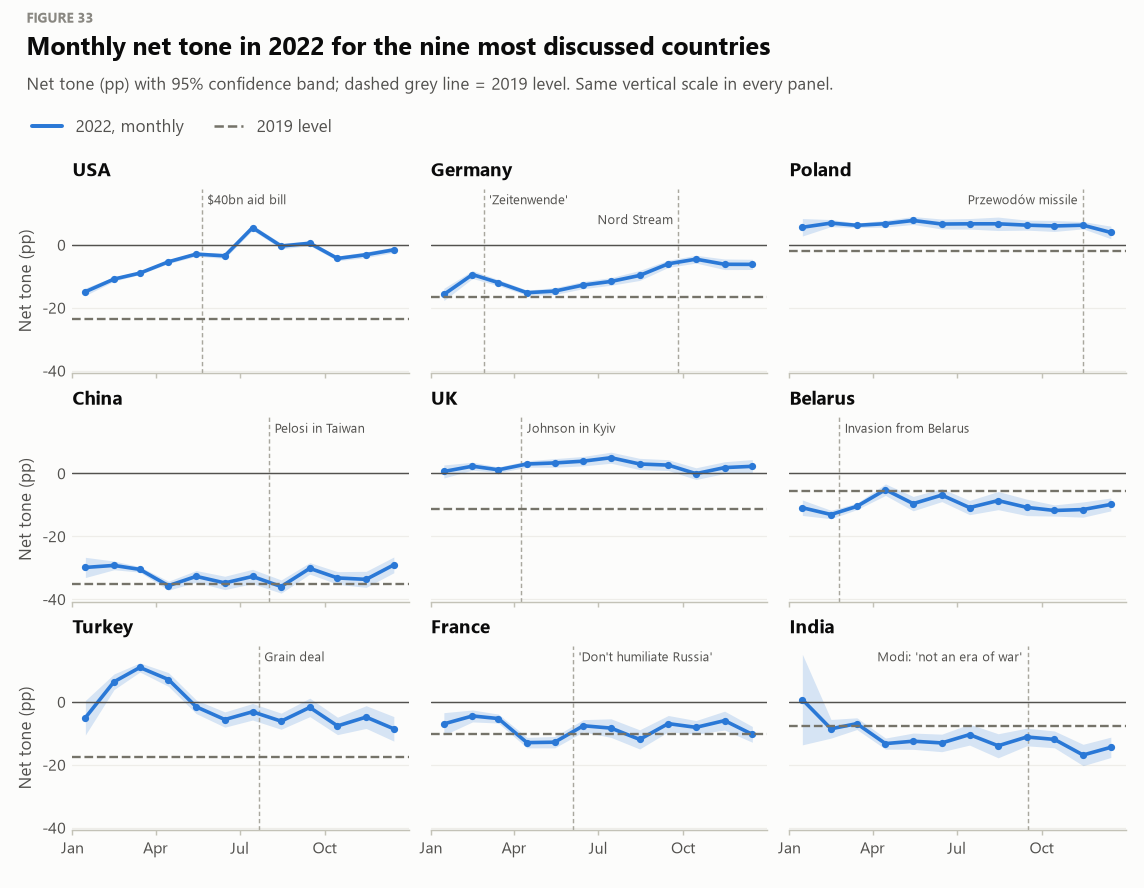

In [36]:
mt_all = net_table(RC[(RC["year"] == 2022) & RC["ent"].isin(ALLIES9)].assign(ent=lambda t: t["ent"].astype(str)),
                   ["ent", "mon"])
n19 = PT["net"].unstack()["2019"] * 100 if "2019" in PT["net"].unstack() else pd.Series(dtype=float)
FIGREF["tone_allies"] = FIG["n"] + 1
fig, axes = frame("Monthly net tone in 2022 for the nine most discussed countries",
                  "Net tone (pp) with 95% confidence band; dashed grey line = 2019 level. Same vertical scale in every panel.",
                  nrows=3, ncols=3, h=6.4, sharex=True, sharey=True,
                  legend=([line_h(BLUE), line_h(C19, lw=1.4, ls="--")], ["2022, monthly", "2019 level"]))
for ax, e in zip(axes.ravel(), ALLIES9):
    if e not in mt_all.index.get_level_values(0):
        ax.set_visible(False)
        continue
    t = mt_all.loc[e].reindex(range(1, 13))
    t = t[t["n"] >= 30]
    xd = pd.to_datetime([f"2022-{m:02d}-15" for m in t.index])
    ax.fill_between(xd, (t["net"] - 1.96 * t["se"]) * 100, (t["net"] + 1.96 * t["se"]) * 100, color=BLUE, alpha=0.18, lw=0)
    ax.plot(xd, t["net"] * 100, color=BLUE, lw=2, marker="o", ms=3)
    if e in n19.index and nn.loc[e].get("2019", 0) >= 100:
        ax.axhline(n19[e], color=C19, lw=1.3, ls="--")
    ax.axhline(0, color=INK2, lw=0.8)
    month_axis(ax, step=3)
    ax.set_title(e)
    mark_events(ax, ENTITY_EVENTS.get(e, []), mode="label")
for ax in axes[:, 0]:
    ax.set_ylabel("Net tone (pp)")
    ax.yaxis.set_major_formatter(SIGNED)
plt.show()
rng_ = {e: (mt_all.loc[e]["net"].idxmax(), mt_all.loc[e]["net"].max(), mt_all.loc[e]["net"].idxmin(), mt_all.loc[e]["net"].min())
        for e in ALLIES9 if e in mt_all.index.get_level_values(0)}
say(*[f"{e}: warmest in {MONTHS_FULL[a - 1]} ({b * 100:+.0f}), coldest in {MONTHS_FULL[c - 1]} ({d * 100:+.0f})."
      for e, (a, b, c, d) in rng_.items()])

**What we see.** The USA line rises from below zero in January to around zero in summer. Germany slowly improves. Turkey is positive in spring and then falls below zero. Poland and the UK stay above zero all year. India goes down in autumn.

**What it means.** Tone follows what countries do: more American help — a warmer tone. Turkey was praised in spring for its Bayraktar drones and for closing the straits to Russian warships, but criticised after it blocked Finland's and Sweden's NATO bid.

## 6. Interesting findings: relationships (Q8, Q9)

### 6.1 Does more attention come with a warmer tone? (Q8)

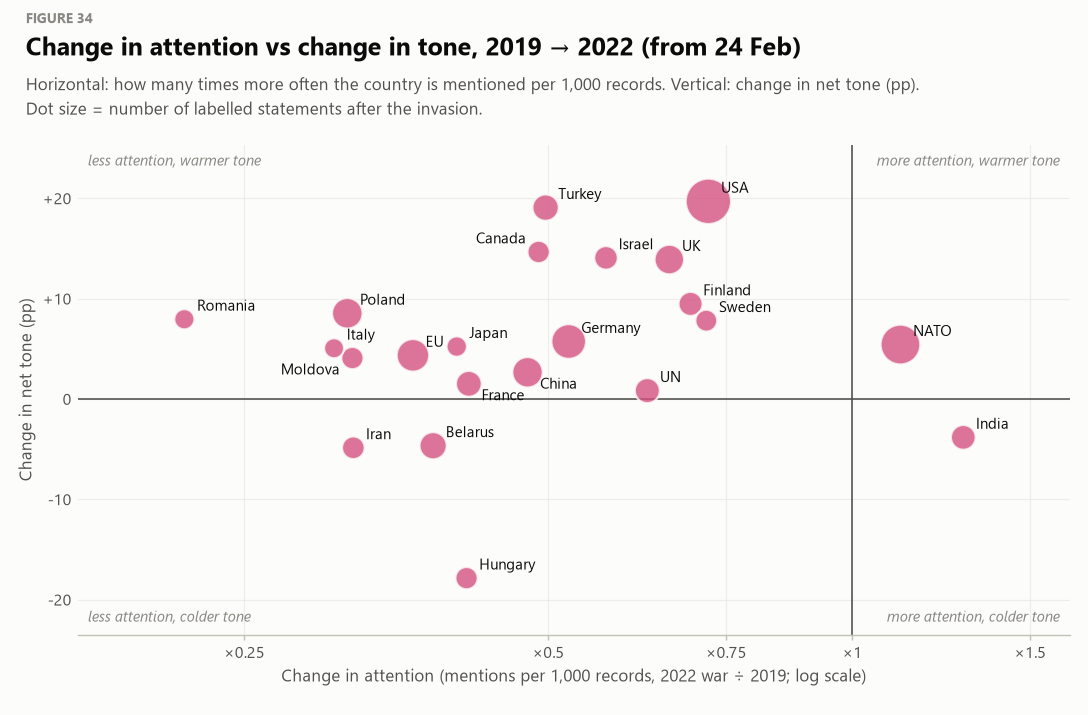

In [37]:
q = pd.DataFrame({"att": RATE["2022_war"] / RATE["2019"], "dnet": net["2022_war"] - net["2019"],
                  "n": nn.loc[net.index, "2022_war"]}).replace([np.inf, -np.inf], np.nan).dropna()
q = q[q["att"] > 0]
FIGREF["quadrant"] = FIG["n"] + 1
fig, ax = frame("Change in attention vs change in tone, 2019 → 2022 (from 24 Feb)",
                "Horizontal: how many times more often the country is mentioned per 1,000 records. Vertical: change in "
                "net tone (pp). Dot size = number of labelled statements after the invasion.",
                h=5.0, w=9.5)
xs = np.log2(q["att"])
sizes = 30 + 600 * np.sqrt(q["n"] / q["n"].max())
ax.scatter(xs, q["dnet"], s=sizes, color=PINK, alpha=0.8, edgecolor=SURFACE, linewidth=1.2, zorder=3)
ax.axhline(0, color=INK2, lw=0.9)
ax.axvline(0, color=INK2, lw=0.9)
texts = []
for e, xv, yv in zip(q.index, xs, q["dnet"]):
    texts.append(ax.annotate(e, xy=(xv, yv), xytext=(6, 4), textcoords="offset points", fontsize=8.3, color=INK))
lo_x, hi_x = min(xs.min(), 0) - 0.35, max(xs.max(), 0) + 0.35
cand_t = [0.125, 0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 6, 8, 16, 32]
xt = [t for t in cand_t if lo_x <= np.log2(t) <= hi_x]
ax.set_xticks(np.log2(xt), [f"×{t:g}" for t in xt])
ax.set_xlim(lo_x, hi_x)
pad = (q["dnet"].max() - q["dnet"].min()) * 0.15
ax.set_ylim(q["dnet"].min() - pad, q["dnet"].max() + pad)
ax.grid(axis="x")
ax.yaxis.set_major_formatter(SIGNED)
ax.set_xlabel("Change in attention (mentions per 1,000 records, 2022 war ÷ 2019; log scale)")
ax.set_ylabel("Change in net tone (pp)")
for (hx, hy, txt) in ((0.99, 0.98, "more attention, warmer tone"), (0.01, 0.98, "less attention, warmer tone"),
                      (0.99, 0.02, "more attention, colder tone"), (0.01, 0.02, "less attention, colder tone")):
    ax.text(hx, hy, txt, transform=ax.transAxes, ha="right" if hx > 0.5 else "left", va="top" if hy > 0.5 else "bottom",
            fontsize=8.3, color=MUTED, style="italic")
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
obstacles = []
for (xv, yv), s_ in zip(zip(xs, q["dnet"]), sizes):      # the dots themselves
    cx, cy = ax.transData.transform((xv, yv))
    r = np.sqrt(s_) / 2 * fig.dpi / 72
    obstacles.append(mpl.transforms.Bbox([[cx - r, cy - r], [cx + r, cy + r]]))
spots = [(7, 3, "left", "bottom"), (7, -3, "left", "top"), (-7, 3, "right", "bottom"), (-7, -3, "right", "top"),
         (0, 9, "center", "bottom"), (0, -9, "center", "top"), (14, 10, "left", "bottom"), (14, -10, "left", "top"),
         (-14, 10, "right", "bottom"), (-14, -10, "right", "top"), (0, 18, "center", "bottom"), (0, -18, "center", "top")]
axbox = ax.get_window_extent(renderer)
placed = []
for t, s_ in sorted(zip(texts, sizes), key=lambda z: -z[1]):
    for dx, dy, ha, va in spots:
        t.set_position((dx, dy)); t.set_ha(ha); t.set_va(va)
        bb = t.get_window_extent(renderer)
        own = [o for o in obstacles if not o.contains(*ax.transData.transform(t.xy))]
        inside = axbox.contains(bb.x0, bb.y0) and axbox.contains(bb.x1, bb.y1)
        if inside and not any(bb.overlaps(o) for o in placed + own):
            break
    else:
        t.set_position((7, 3)); t.set_ha("left"); t.set_va("bottom")
    placed.append(t.get_window_extent(renderer))
plt.show()
r_ = np.corrcoef(xs, q["dnet"])[0, 1] if len(q) > 2 else np.nan
FACTS["att_tone_r"] = r_
say(f"Across {len(q)} countries the correlation between the change in attention (log) and the change in tone is "
    f"**r = {r_:.2f}**: " + ("countries that gained attention also tended to gain a warmer tone." if r_ > 0.3 else
                              "countries that gained attention tended to be talked about more coldly." if r_ < -0.3 else
                              "attention and tone moved largely independently — being discussed more did not mean being liked more."),
    "More attention and a warmer tone: " + (", ".join(q[(xs > 0) & (q["dnet"] > 0)].sort_values("dnet", ascending=False).index[:6]) or "none") + ".",
    "More attention but a colder tone: " + (", ".join(q[(xs > 0) & (q["dnet"] < 0)].sort_values("dnet").index[:6]) or "none") + ".",
    "Less attention but a warmer tone: " + (", ".join(q[(xs < 0) & (q["dnet"] > 0)].sort_values("dnet", ascending=False).index[:6]) or "none") + ".")

**What we see.** Most dots are in the upper left part: countries were mentioned relatively less often but became warmer. NATO is in the upper right, India in the lower right, Hungary far below.

**What it means.** More attention did not automatically mean a better image. What mattered was what the country did: helping Ukraine made the tone warmer.

### 6.2 Do communities differ in tone?

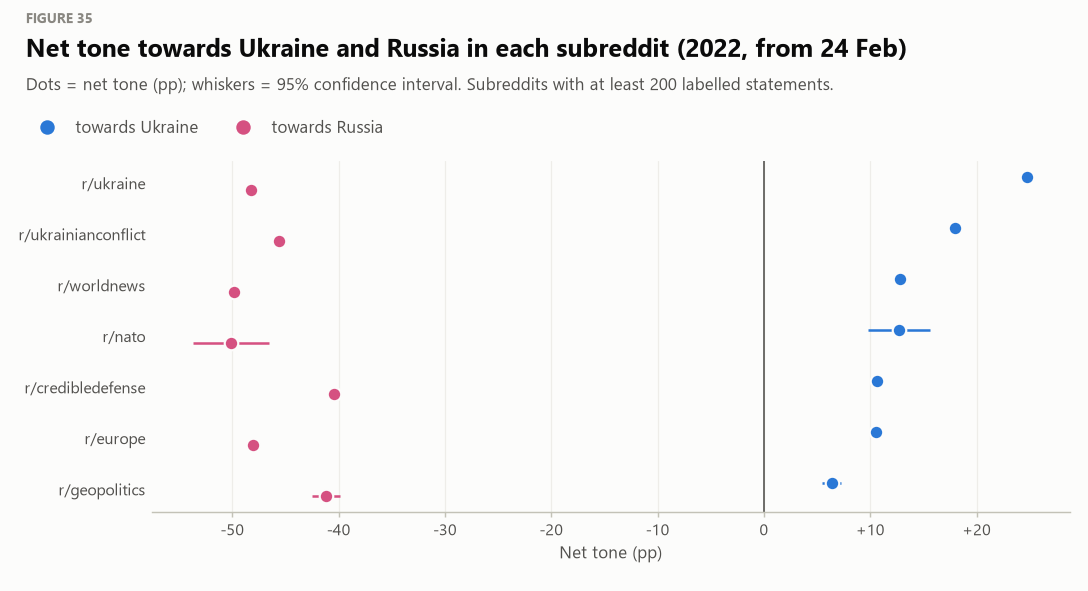

In [38]:
sub_t = net_table(RC[(RC["per"] == 2) & RC["ent"].isin(["Ukraine", "Russia"])].assign(ent=lambda t: t["ent"].astype(str)),
                  ["sub", "ent"])
sub_t = sub_t[sub_t["n"] >= 200]
ua = sub_t.xs("Ukraine", level="ent")["net"].sort_values()
order_sub = [s for s in ua.index]
fig, ax = frame("Net tone towards Ukraine and Russia in each subreddit (2022, from 24 Feb)",
                "Dots = net tone (pp); whiskers = 95% confidence interval. Subreddits with at least 200 labelled statements.",
                h=0.42 * len(order_sub) + 0.8, w=9.5,
                legend=([dot_h(BLUE), dot_h(RUSSIA_COLOR)], ["towards Ukraine", "towards Russia"]))
for i, s in enumerate(order_sub):
    for e, c, dy in (("Ukraine", BLUE, 0.13), ("Russia", RUSSIA_COLOR, -0.13)):
        if (s, e) not in sub_t.index:
            continue
        r = sub_t.loc[(s, e)]
        ax.hlines(i + dy, (r["net"] - 1.96 * r["se"]) * 100, (r["net"] + 1.96 * r["se"]) * 100, color=c, lw=1.4)
        ax.plot(r["net"] * 100, i + dy, "o", color=c, ms=7.5, mec=SURFACE, mew=1.2, zorder=3)
ax.set_yticks(range(len(order_sub)), [f"r/{s}" for s in order_sub])
ax.axvline(0, color=INK2, lw=0.9)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(SIGNED)
ax.set_xlabel("Net tone (pp)")
plt.show()
ru = sub_t.xs("Russia", level="ent")["net"]
neu_sub = net_table(RC[(RC["per"] == 2) & RC["ent"].isin(["Ukraine", "Russia"])], ["sub"])
neu_sub = neu_sub[neu_sub["n"] >= 200]["neu_share"]
say(f"Warmest towards Ukraine: r/{ua.idxmax()} ({ua.max() * 100:+.0f}); coolest: r/{ua.idxmin()} ({ua.min() * 100:+.0f}).",
    f"Most negative towards Russia: r/{ru.idxmin()} ({ru.min() * 100:+.0f}); least negative: r/{ru.idxmax()} ({ru.max() * 100:+.0f}).",
    f"Most neutral community (statements about Ukraine and Russia): r/{neu_sub.idxmax()} ({neu_sub.max():.0%} neutral); "
    f"least neutral: r/{neu_sub.idxmin()} ({neu_sub.min():.0%}).")

**What we see.** All blue dots are to the right of zero and all pink dots to the left. r/ukraine is the warmest towards Ukraine; r/geopolitics is the closest to zero for both countries.

**What it means.** All communities support Ukraine and criticise Russia, but analytical communities like r/geopolitics write in a more neutral way.

### 6.3 Does Reddit reward hostile or supportive statements? (Q9)

For comments after the invasion we compute each comment's **score percentile within its subreddit and week** (so that a big subreddit or a busy week does not distort the comparison) and check how often comments with each tone end up in the top 10%.

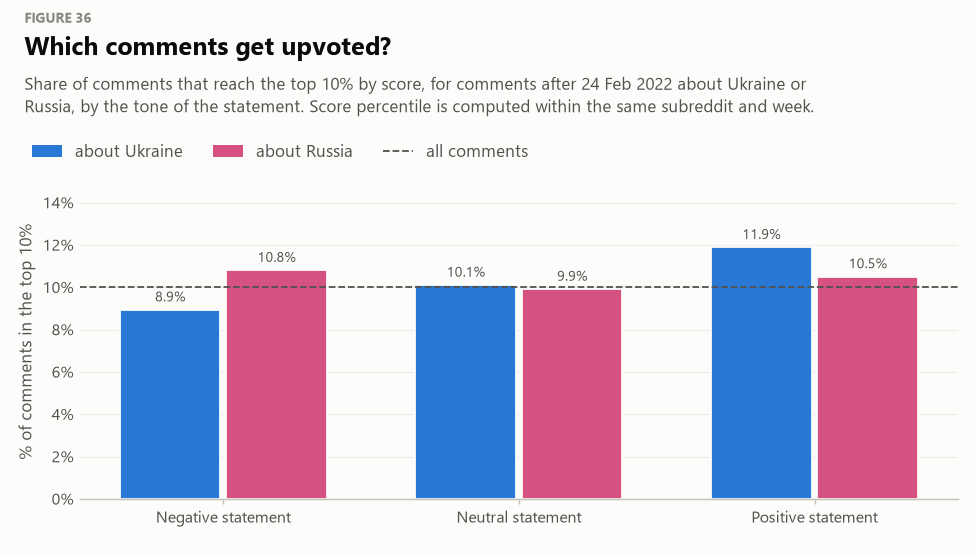

In [39]:
cm_mask = (R["per"] == 2) & (R["type"] == "comment") & R["core"]
pct = R.loc[cm_mask].groupby(["sub", "week"], observed=True)["score"].rank(pct=True)
top10 = pd.Series(False, index=R.index)
top10.loc[pct.index] = pct >= 0.9
base_rate = top10[cm_mask].mean()
TR = RC[(RC["per"] == 2) & (RC["type"] == "comment") & RC["ent"].isin(["Ukraine", "Russia"])]
TR = TR.assign(top=top10.to_numpy()[TR["row"].to_numpy()], ent=TR["ent"].astype(str))
ts = TR.groupby(["ent", "v"])["top"].agg(["mean", "size"]).reset_index()
FIGREF["upvotes"] = FIG["n"] + 1
fig, ax = frame("Which comments get upvoted?",
                "Share of comments that reach the top 10% by score, for comments after 24 Feb 2022 about Ukraine or "
                "Russia, by the tone of the statement. "
                "Score percentile is computed within the same subreddit and week.",
                h=3.2, w=8.5, legend=([patch_h(BLUE), patch_h(RUSSIA_COLOR), line_h(INK2, lw=1, ls="--")],
                                      ["about Ukraine", "about Russia", "all comments"]))
xs = np.arange(3)
for k, (e, c) in enumerate((("Ukraine", BLUE), ("Russia", RUSSIA_COLOR))):
    v = ts[ts["ent"] == e].set_index("v").reindex([-1, 0, 1])
    bars = ax.bar(xs + (k - 0.5) * 0.36, v["mean"] * 100, width=0.34, color=c, edgecolor=SURFACE, linewidth=1)
    for xb, val in zip(xs + (k - 0.5) * 0.36, v["mean"] * 100):
        ax.text(xb, val + 0.25, f"{val:.1f}%", ha="center", va="bottom", fontsize=8, color=INK2)
ax.axhline(base_rate * 100, color=INK2, lw=1, ls="--")
ax.set_xticks(xs, ["Negative statement", "Neutral statement", "Positive statement"])
ax.yaxis.set_major_formatter(pct_fmt())
ax.set_ylabel("% of comments in the top 10%")
ax.set_ylim(0, max(ts["mean"].max() * 100 * 1.25, base_rate * 100 * 1.3))
plt.show()
g_ = ts.set_index(["ent", "v"])["mean"]
FACTS["upvotes"] = g_
ru_neg, ru_neu = g_.get(("Russia", -1), np.nan), g_.get(("Russia", 0), np.nan)
ua_pos, ua_neu, ua_neg = g_.get(("Ukraine", 1), np.nan), g_.get(("Ukraine", 0), np.nan), g_.get(("Ukraine", -1), np.nan)
FACTS["upvote_ratio_ru_neg"], FACTS["upvote_ratio_ua_pos"] = ru_neg / ru_neu, ua_pos / ua_neu
if ru_neg > ru_neu * 1.1 and ua_pos > ua_neu * 1.1:
    verdict_ = ("Evaluative comments are rewarded: hostile statements about Russia and supportive statements about Ukraine "
                "reach the top 10% more often than neutral ones. Reddit's voting amplifies opinion, not just information.")
elif ru_neg > ru_neu * 1.1 or ua_pos > ua_neu * 1.1:
    verdict_ = "Only one kind of evaluative statement gets an upvote bonus; the other scores like neutral comments."
else:
    verdict_ = "Tone makes little difference to upvotes: neutral, informative comments do as well as evaluative ones."
say(f"Across all wartime comments {base_rate:.1%} reach the top 10% (ties make it slightly lower than 10%).",
    f"About Russia: negative {ru_neg:.1%} vs neutral {ru_neu:.1%} (×{ru_neg / ru_neu:.2f}); "
    f"about Ukraine: positive {ua_pos:.1%} vs neutral {ua_neu:.1%} (×{ua_pos / ua_neu:.2f}), negative {ua_neg:.1%}.",
    verdict_)

**What we see.** The blue bar for positive statements is the highest, and the blue bar for negative statements is the lowest. For Russia, negative comments are only a little above the dashed line.

**What it means.** Reddit users reward support for Ukraine with upvotes and are less likely to upvote criticism of Ukraine.

## 7. Conclusions

### 7.1 Hypotheses checked against the data

| # | Hypothesis | Result | What the figures show |
|---|---|---|---|
| **H1** | Much more discussion in 2022, also as a share of each subreddit's activity | Partly supported | Dozens of times more records. As a share of activity the growth is huge in general news subreddits, but not in the Ukrainian ones, which were always about Ukraine (Fig. 1–2) |
| **H2** | A peak at the start of the invasion, then a decline with smaller spikes at big events | Supported | The peak is at the end of February; half of it is gone in about two weeks; smaller waves come in autumn (Fig. 3–4) |
| **H3** | In 2019 Ukraine was discussed mainly through US politics | Partly supported | True for autumn 2019, after the impeachment started; not for the first half of the year (Fig. 5, 15) |
| **H4** | Wartime discussion is concentrated in megathreads | Partly supported | A few big threads matter in every period; the strongest concentration is just before the invasion (Fig. 11) |
| **H5** | Attention moves from the USA to European neighbours | Not supported | The USA stays far ahead; most countries are mentioned relatively less, because the war itself takes over the conversation (Fig. 16–19) |
| **H6** | Military aid and sanctions dominate; energy grows in autumn | Partly supported | Military aid is the main topic and sanctions follow; energy does not grow in autumn (Fig. 21–24) |
| **H7** | Ukraine warmer, Russia colder; Hungary colder, Poland and UK warmer | Supported | Every part is confirmed (Fig. 29–33) |
| **H8** | Countries discussed more after the invasion are also talked about more warmly | Not supported | There is no link: most countries were mentioned relatively less but became warmer; what mattered was whether the country helped Ukraine (Fig. 34) |
| **H9** | Comments that support Ukraine or criticise Russia get more upvotes than neutral ones | Partly supported | Comments praising Ukraine clearly get more upvotes and comments criticising Ukraine fewer; criticism of Russia gets only a small bonus (Fig. 36) |

### 7.2 Main conclusions

1. **The war turned a side topic into a main topic.** In 2019 Ukraine was a small topic on Reddit, and in the autumn much of it was really about the US impeachment. In 2022 there were dozens of times more posts and comments, and Ukraine took a large part of general news subreddits.
2. **Attention follows the news.** The biggest wave came right after the invasion. It faded within a few weeks but never went back to the 2019 level, and smaller waves came with the counteroffensive, mobilisation, Kherson and the missile in Poland.
3. **The discussion moved to war communities and became faster.** After the invasion much more of the talk happened in war subreddits and threads; comments became shorter, people wrote at weekends almost as much as on weekdays, and posts got many more upvotes.
4. **The conversation is about the war itself.** Putin is the most named person, and words like *weapons*, *soldiers* and *artillery* replaced *Crimea*, *annexation* and *elections* from 2019. Each country has its own role: the USA, the UK, Poland and Turkey — weapons; Germany and Norway — energy; Finland and Sweden — NATO; China, India and Iran — sanctions and Russian oil.
5. **Weapons and themes follow the timeline of the war.** Portable weapons in spring, HIMARS in summer, Iranian drones in autumn, Patriot in December; war crimes after Bucha, nuclear fear and mobilisation in September, talk about negotiations in November.
6. **Support for Ukraine, anger at Russia.** The tone towards Ukraine became much warmer and the tone towards Russia, already negative, became even colder. Countries that helped Ukraine were talked about more warmly; Hungary, Belarus and Iran — more coldly.
7. **Reddit rewards support for Ukraine.** Comments that praise Ukraine get many upvotes more often than neutral ones, and comments that criticise Ukraine get them less often.

